# Routing method comparison: all metrics

This notebook calls `return_ops_all_methods` once for each graph parameter. Each call collects SWAP counts after routing, two-qubit gate counts and circuit depth after optimization, and transpilation time for both paths.

## Imports and backend

In [1]:
from helper_functions import (
    return_ops_all_methods,
    return_times_all_methods,
    plot_metric_results,
)
from qiskit_ibm_runtime.fake_provider import FakeMarrakesh
from IPython.display import display
import pandas as pd
import warnings
warnings.filterwarnings("ignore")

backend = FakeMarrakesh()

## Experiment configuration

In [2]:
k_list = [2, 3, 4]
average_over = 10
reps = 1
opt_level = 1

# Keep the graph sizes and parameter ranges comparable to comparison_plots_final.ipynb.
nodes_reg = list(range(10, 101, 2))
params_reg = list(range(3, 9))
nodes_ba = list(range(6, 101, 2))
params_ba = list(range(2, 5))

## Collect all metrics

The function internally runs both routing paths, so each parameter only needs one call.

In [3]:
results_reg = {}
for param in params_reg:
    results_reg[param] = return_ops_all_methods(
        backend,
        graph_type='reg',
        param=param,
        average_over=average_over,
        node_list=nodes_reg,
        k_list=k_list,
        reps=reps,
        opt_level=opt_level,
        noise_aware=True,
    )

results_ba = {}
for param in params_ba:
    results_ba[param] = return_ops_all_methods(
        backend,
        graph_type='ba',
        param=param,
        average_over=average_over,
        node_list=nodes_ba,
        k_list=k_list,
        reps=reps,
        opt_level=opt_level,
        noise_aware=True,
    )

# Timing is kept separate from circuit-quality metrics so every stage can be compared fairly.
times_reg = {}
for param in params_reg:
    times_reg[param] = return_times_all_methods(
        backend,
        graph_type='reg',
        param=param,
        average_over=average_over,
        node_list=nodes_reg,
        k_list=k_list,
        reps=reps,
        opt_level=opt_level,
        noise_aware=True,
    )

times_ba = {}
for param in params_ba:
    times_ba[param] = return_times_all_methods(
        backend,
        graph_type='ba',
        param=param,
        average_over=average_over,
        node_list=nodes_ba,
        k_list=k_list,
        reps=reps,
        opt_level=opt_level,
        noise_aware=True,
    )

## Tables of collected values

Each cell reports the mean and standard deviation across repeated runs as `mean ± std`.

In [4]:
def metric_table(results, node_list, params, metric, methods):
    rows = []
    for param in params:
        statistics = results[param]
        for key in metric.split('.'):
            statistics = statistics[key]

        for index, node_count in enumerate(node_list):
            row = {'Parameter': param, 'Nodes': node_count}
            for method in methods:
                mean = statistics['means'][method][index]
                stddev = statistics['stddevs'][method][index]
                row[method] = f'{mean:.3f} ± {stddev:.3f}'
            rows.append(row)
    return pd.DataFrame(rows)

methods = ['SABRE', 'Trivial', 'FOM'] + [f'SAM{k}' for k in k_list]
quality_metrics = [
    ('swaps', 'SWAP count'),
    ('two_qubit_gates', 'Two-qubit gate count'),
    ('circuit_depth', 'Optimized circuit depth'),
]
time_metrics = [
    ('mapping_time', 'Mapping time (seconds)'),
    ('circuit_generation_time', 'Initial circuit generation time (seconds)'),
    ('routing_time', 'Routing time (seconds)'),
    ('optimization_time', 'Final optimization time (seconds)'),
]

for graph_name, results, times, nodes, params in [
    ('Random regular graphs', results_reg, times_reg, nodes_reg, params_reg),
    ('Barabasi-Albert graphs', results_ba, times_ba, nodes_ba, params_ba),
]:
    print(f'\n{graph_name}')
    for metric, label in quality_metrics:
        print(f'\n{label}')
        display(metric_table(results, nodes, params, metric, methods))
    for metric, label in time_metrics:
        print(f'\n{label}')
        display(metric_table(times, nodes, params, metric, methods))


Random regular graphs

SWAP count


,Parameter,Nodes,SABRE,Trivial,FOM,SAM2,SAM3,SAM4
0,3,10,10.000 ± 0.000,25.700 ± 0.781,10.000 ± 0.000,12.000 ± 0.000,13.000 ± 0.000,14.000 ± 0.000
1,3,12,15.000 ± 0.000,45.600 ± 0.800,20.000 ± 0.000,21.600 ± 0.490,16.000 ± 0.000,16.000 ± 0.000
2,3,14,19.200 ± 0.400,48.000 ± 0.000,20.200 ± 0.400,23.000 ± 0.000,20.400 ± 0.490,26.000 ± 0.000
3,3,16,26.600 ± 0.490,74.200 ± 1.720,31.000 ± 0.000,27.700 ± 0.900,22.000 ± 0.000,25.000 ± 0.000
4,3,18,25.200 ± 0.400,93.800 ± 3.736,31.000 ± 0.000,30.600 ± 1.281,27.000 ± 0.000,27.700 ± 0.781
...,...,...,...,...,...,...,...,...
271,8,92,1610.200 ± 17.865,2017.000 ± 22.082,1319.600 ± 27.306,1330.000 ± 30.087,1289.600 ± 29.568,1298.900 ± 24.135
272,8,94,1744.400 ± 24.426,2006.200 ± 18.340,1386.500 ± 15.370,1443.900 ± 7.803,1363.700 ± 24.739,1269.800 ± 17.354
273,8,96,1804.800 ± 19.281,2173.600 ± 25.676,1480.500 ± 23.863,1465.600 ± 18.478,1449.500 ± 16.848,1390.800 ± 29.140
274,8,98,1841.600 ± 27.814,2220.100 ± 20.714,1523.000 ± 23.147,1450.900 ± 18.030,1473.500 ± 24.467,1439.200 ± 22.860



Two-qubit gate count


,Parameter,Nodes,SABRE,Trivial,FOM,SAM2,SAM3,SAM4
0,3,10,60.000 ± 0.000,107.100 ± 2.343,60.000 ± 0.000,66.000 ± 0.000,69.000 ± 0.000,72.000 ± 0.000
1,3,12,81.000 ± 0.000,172.800 ± 2.400,96.000 ± 0.000,100.800 ± 1.470,84.000 ± 0.000,84.000 ± 0.000
2,3,14,99.600 ± 1.200,186.000 ± 0.000,102.600 ± 1.200,111.000 ± 0.000,103.200 ± 1.470,120.000 ± 0.000
3,3,16,127.800 ± 1.470,270.600 ± 5.161,141.000 ± 0.000,131.100 ± 2.700,114.000 ± 0.000,123.000 ± 0.000
4,3,18,129.600 ± 1.200,335.400 ± 11.209,147.000 ± 0.000,145.800 ± 3.842,135.000 ± 0.000,137.100 ± 2.343
...,...,...,...,...,...,...,...,...
271,8,92,5566.600 ± 53.595,6787.000 ± 66.245,4694.800 ± 81.919,4726.000 ± 90.260,4604.800 ± 88.703,4632.700 ± 72.404
272,8,94,5985.200 ± 73.279,6770.600 ± 55.020,4911.500 ± 46.111,5083.700 ± 23.410,4843.100 ± 74.217,4561.400 ± 52.062
273,8,96,6182.400 ± 57.843,7288.800 ± 77.027,5209.500 ± 71.589,5164.800 ± 55.434,5116.500 ± 50.544,4940.400 ± 87.421
274,8,98,6308.800 ± 83.443,7444.300 ± 62.143,5353.000 ± 69.442,5136.700 ± 54.091,5204.500 ± 73.402,5101.600 ± 68.579



Optimized circuit depth


,Parameter,Nodes,SABRE,Trivial,FOM,SAM2,SAM3,SAM4
0,3,10,90.000 ± 0.000,160.800 ± 5.400,72.400 ± 3.904,99.400 ± 2.939,91.600 ± 3.412,99.400 ± 3.105
1,3,12,102.600 ± 2.800,171.800 ± 9.485,127.300 ± 6.986,113.500 ± 8.628,94.400 ± 3.323,83.000 ± 4.837
2,3,14,112.200 ± 2.400,204.300 ± 7.156,133.600 ± 5.219,113.000 ± 3.521,152.400 ± 10.744,119.800 ± 5.845
3,3,16,167.800 ± 6.735,270.600 ± 11.758,136.600 ± 2.577,138.900 ± 5.540,91.800 ± 4.750,121.800 ± 2.713
4,3,18,158.000 ± 6.148,312.600 ± 28.675,148.300 ± 3.494,120.600 ± 5.903,108.800 ± 3.156,130.000 ± 14.731
...,...,...,...,...,...,...,...,...
271,8,92,3166.500 ± 99.073,3731.200 ± 155.228,1533.200 ± 106.029,1467.900 ± 135.416,1533.100 ± 126.602,1564.600 ± 209.123
272,8,94,3415.900 ± 111.745,3790.000 ± 148.649,1636.500 ± 157.909,1728.000 ± 155.658,1608.200 ± 165.201,1283.700 ± 125.478
273,8,96,4042.100 ± 155.651,4424.700 ± 162.479,1859.400 ± 185.431,1612.300 ± 171.397,1714.200 ± 111.147,1763.500 ± 130.049
274,8,98,3480.100 ± 172.195,4182.000 ± 258.563,1758.600 ± 135.691,1587.600 ± 142.634,1755.300 ± 206.454,1579.400 ± 138.209


... (18 outputs left out)


Routing time (seconds)


,Parameter,Nodes,SABRE,Trivial,FOM,SAM2,SAM3,SAM4
0,2,6,0.002 ± 0.000,0.002 ± 0.000,0.002 ± 0.000,0.002 ± 0.000,0.002 ± 0.000,0.002 ± 0.000
1,2,8,0.003 ± 0.000,0.003 ± 0.000,0.003 ± 0.000,0.002 ± 0.000,0.002 ± 0.000,0.002 ± 0.000
2,2,10,0.003 ± 0.001,0.003 ± 0.000,0.002 ± 0.000,0.002 ± 0.000,0.002 ± 0.000,0.002 ± 0.000
3,2,12,0.003 ± 0.000,0.003 ± 0.001,0.002 ± 0.000,0.002 ± 0.000,0.002 ± 0.000,0.002 ± 0.000
4,2,14,0.003 ± 0.000,0.003 ± 0.000,0.003 ± 0.000,0.003 ± 0.000,0.003 ± 0.000,0.002 ± 0.000
...,...,...,...,...,...,...,...,...
139,4,92,0.006 ± 0.000,0.006 ± 0.000,0.006 ± 0.001,0.006 ± 0.000,0.006 ± 0.000,0.006 ± 0.000
140,4,94,0.006 ± 0.001,0.006 ± 0.001,0.006 ± 0.000,0.006 ± 0.000,0.006 ± 0.000,0.006 ± 0.000
141,4,96,0.006 ± 0.001,0.006 ± 0.000,0.006 ± 0.000,0.006 ± 0.000,0.006 ± 0.000,0.006 ± 0.000
142,4,98,0.006 ± 0.000,0.006 ± 0.000,0.006 ± 0.000,0.006 ± 0.001,0.006 ± 0.000,0.006 ± 0.000



Final optimization time (seconds)


,Parameter,Nodes,SABRE,Trivial,FOM,SAM2,SAM3,SAM4
0,2,6,0.004 ± 0.000,0.004 ± 0.000,0.004 ± 0.000,0.004 ± 0.000,0.004 ± 0.000,0.004 ± 0.000
1,2,8,0.004 ± 0.000,0.004 ± 0.000,0.004 ± 0.000,0.004 ± 0.000,0.004 ± 0.000,0.004 ± 0.000
2,2,10,0.004 ± 0.001,0.005 ± 0.000,0.004 ± 0.000,0.005 ± 0.000,0.004 ± 0.000,0.004 ± 0.000
3,2,12,0.004 ± 0.000,0.005 ± 0.001,0.004 ± 0.000,0.004 ± 0.000,0.005 ± 0.000,0.004 ± 0.000
4,2,14,0.004 ± 0.000,0.005 ± 0.000,0.005 ± 0.000,0.005 ± 0.000,0.005 ± 0.000,0.005 ± 0.000
...,...,...,...,...,...,...,...,...
139,4,92,0.015 ± 0.001,0.016 ± 0.001,0.016 ± 0.003,0.015 ± 0.001,0.016 ± 0.001,0.015 ± 0.001
140,4,94,0.016 ± 0.001,0.016 ± 0.001,0.016 ± 0.001,0.016 ± 0.001,0.015 ± 0.000,0.016 ± 0.001
141,4,96,0.016 ± 0.001,0.017 ± 0.001,0.016 ± 0.001,0.017 ± 0.001,0.016 ± 0.001,0.016 ± 0.001
142,4,98,0.017 ± 0.001,0.017 ± 0.001,0.017 ± 0.003,0.016 ± 0.001,0.016 ± 0.001,0.016 ± 0.001


## Plot the collected metrics

Each line shows the mean across repeated runs; the shaded area shows one standard deviation.

In [5]:
quality_plots = [
    ('swaps', 'SWAP count', 'SWAPs'),
    ('two_qubit_gates', 'Two-qubit gate count', 'Two-qubit gates'),
    ('circuit_depth', 'Optimized circuit depth', 'Circuit depth'),
]
time_plots = [
    ('mapping_time', 'Mapping time', 'Time (seconds)'),
    ('circuit_generation_time', 'Initial circuit generation time', 'Time (seconds)'),
    ('routing_time', 'Routing time', 'Time (seconds)'),
    ('optimization_time', 'Final optimization time', 'Time (seconds)'),
]

# RR Circuit Quality

Random regular graphs: SWAP count


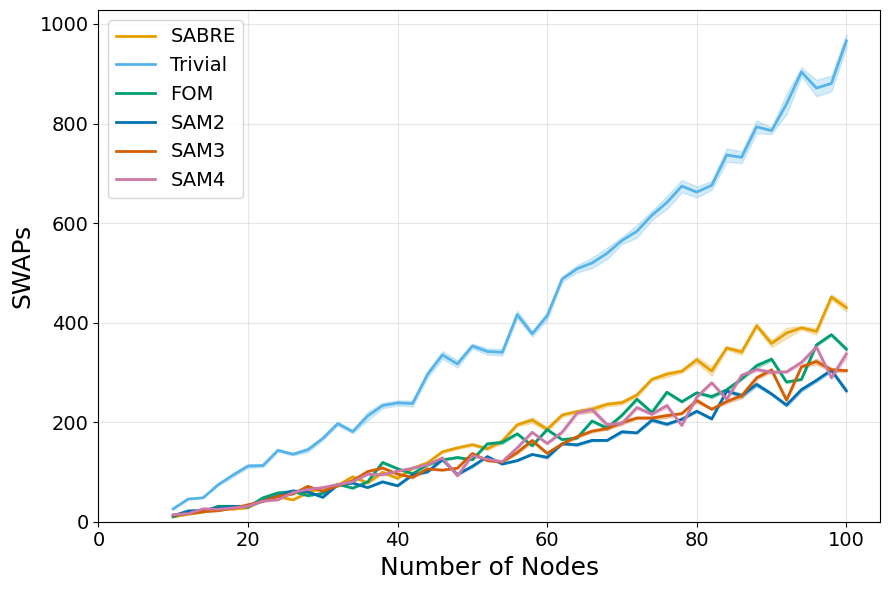

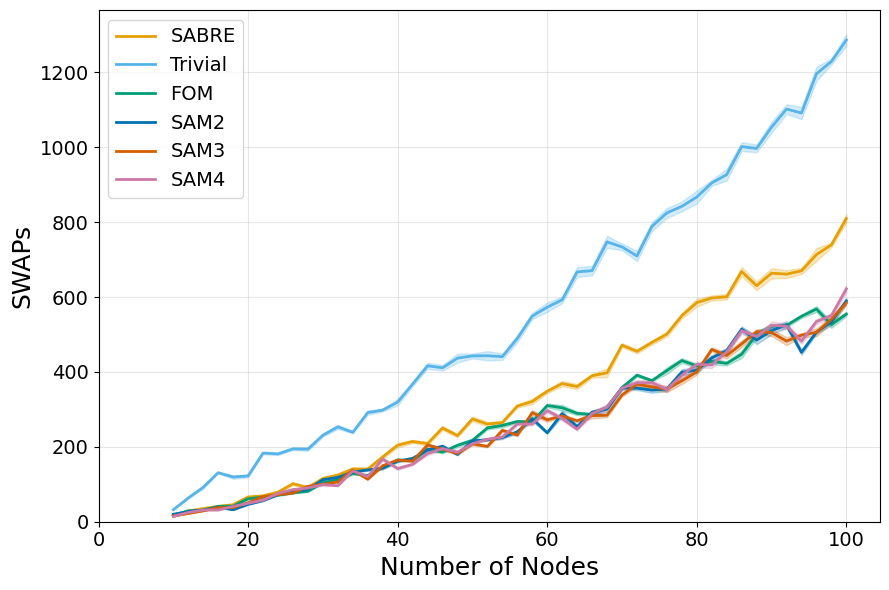

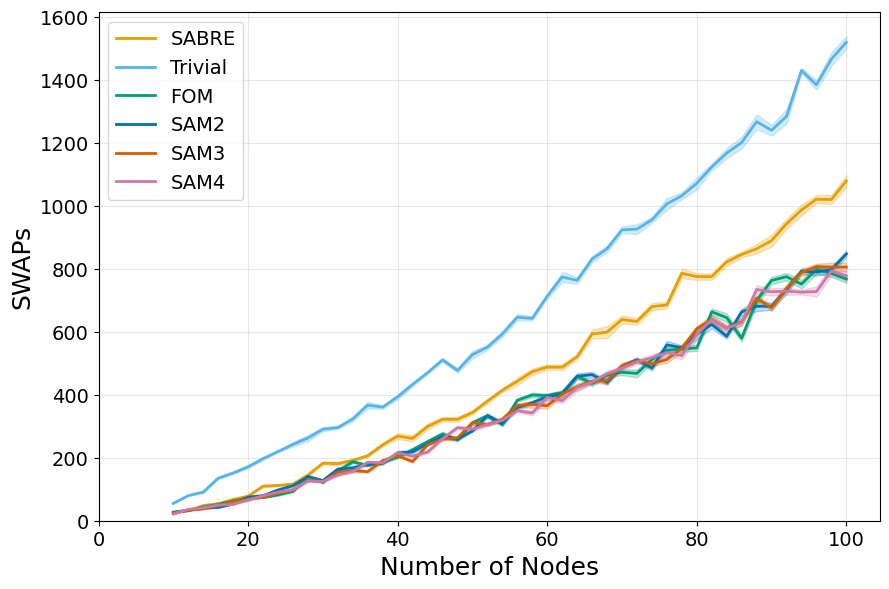

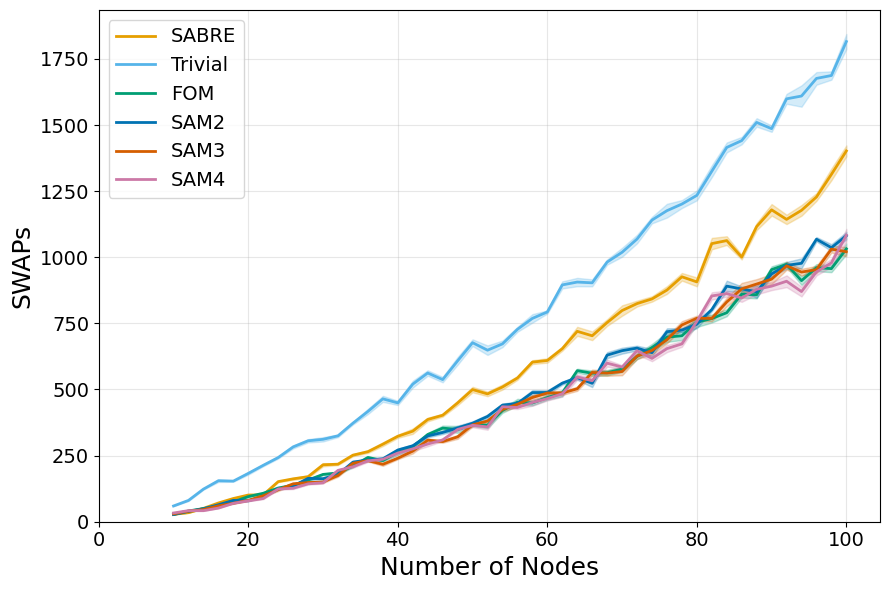

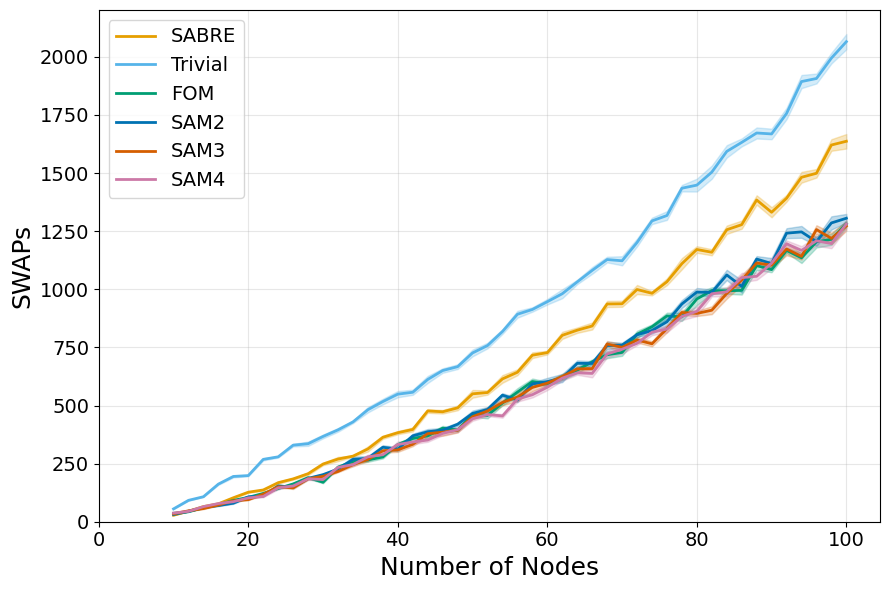

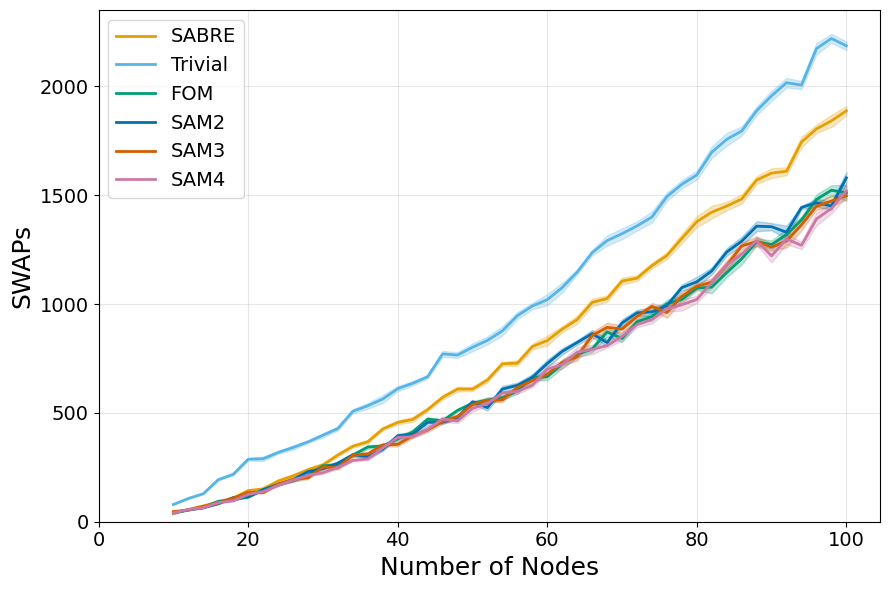

Random regular graphs: Two-qubit gate count


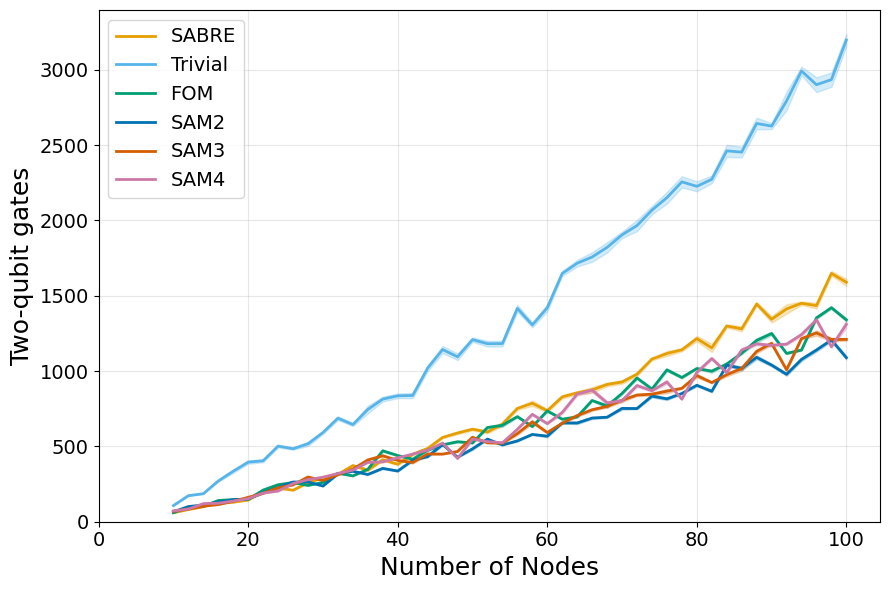

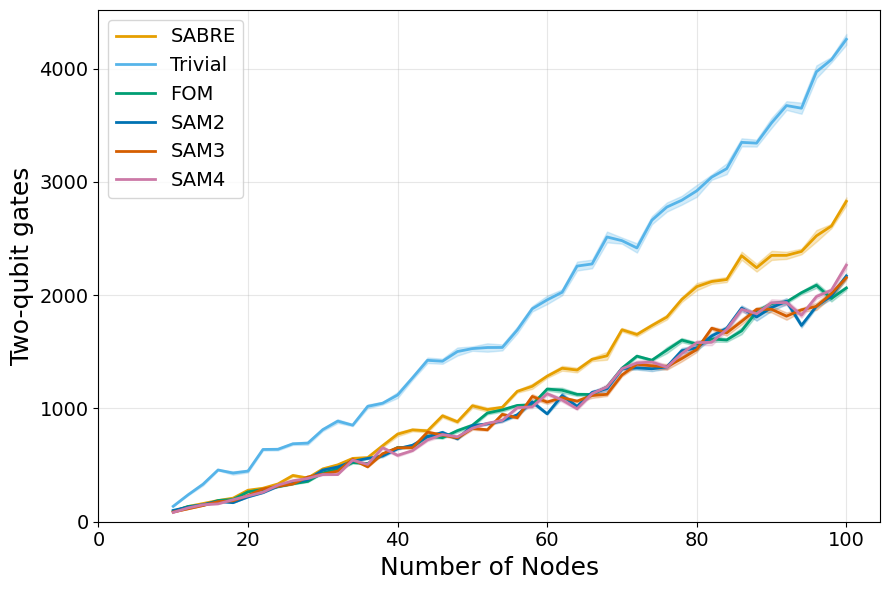

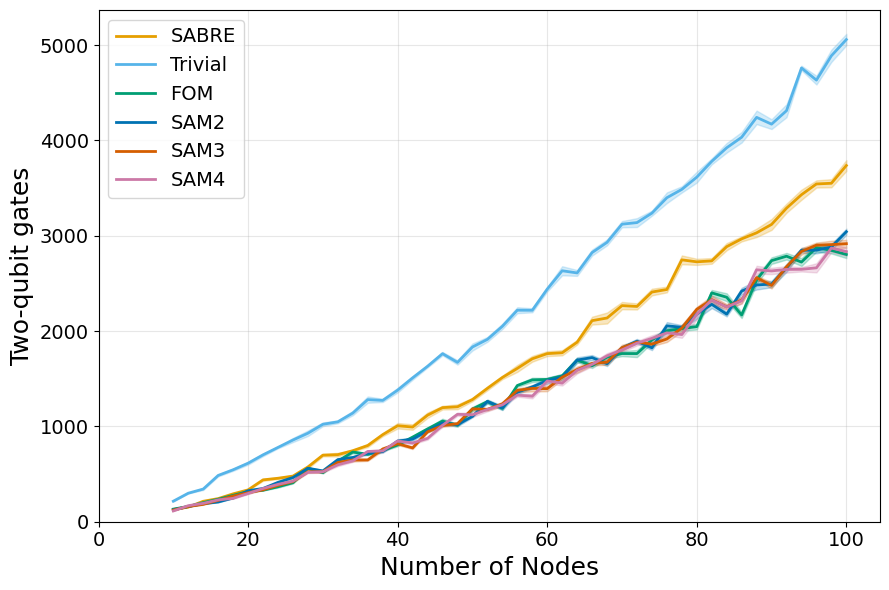

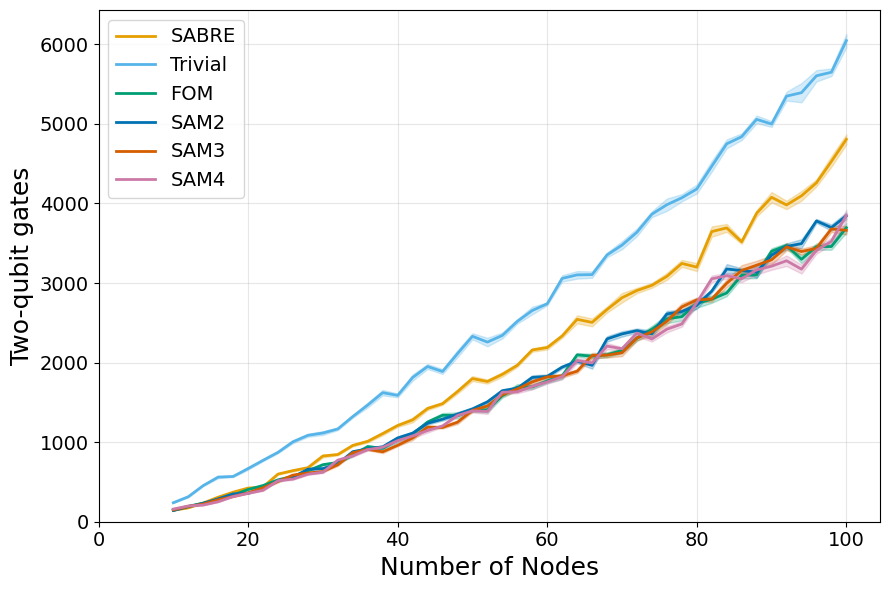

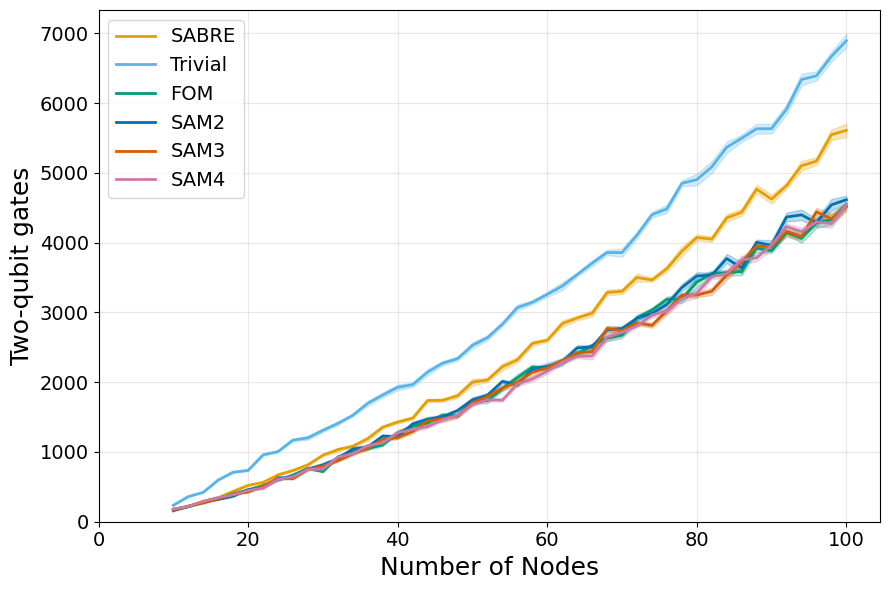

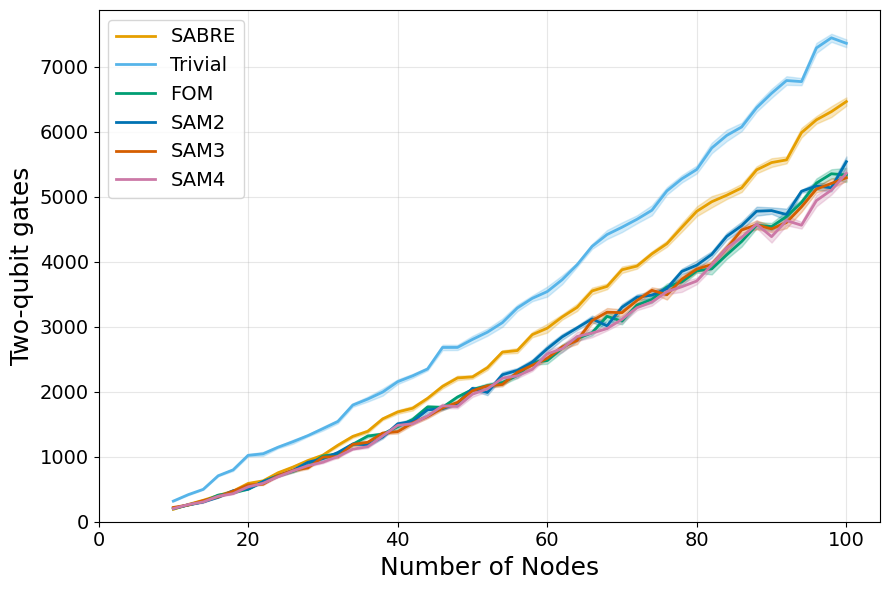

Random regular graphs: Optimized circuit depth


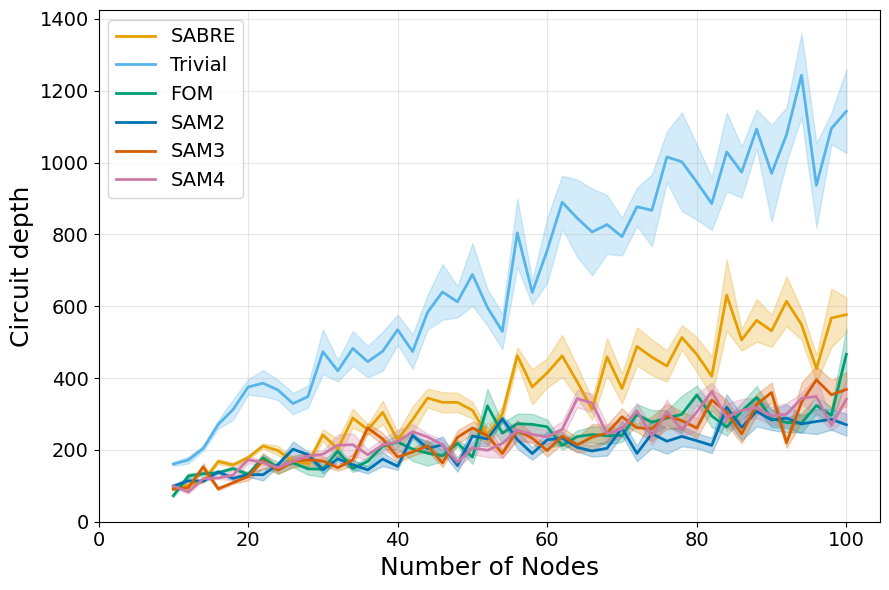

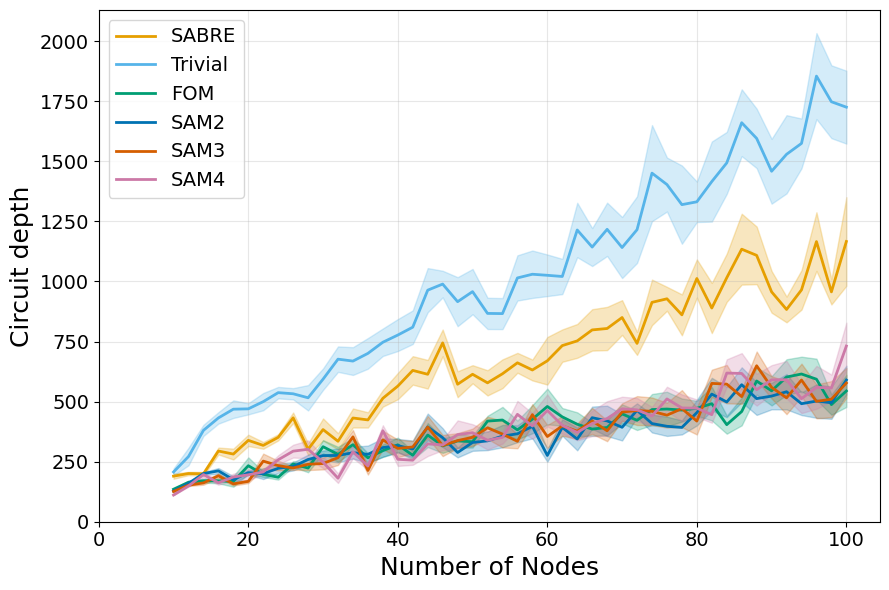

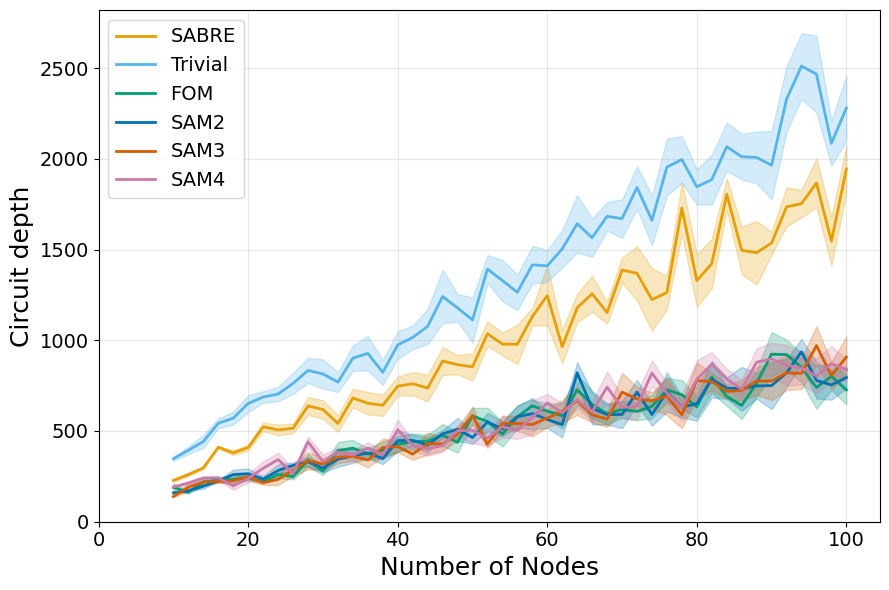

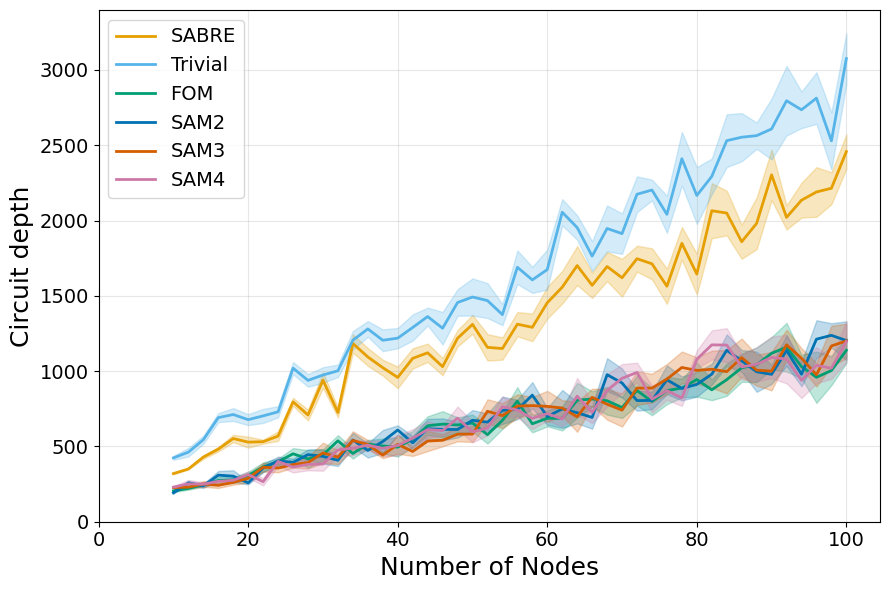

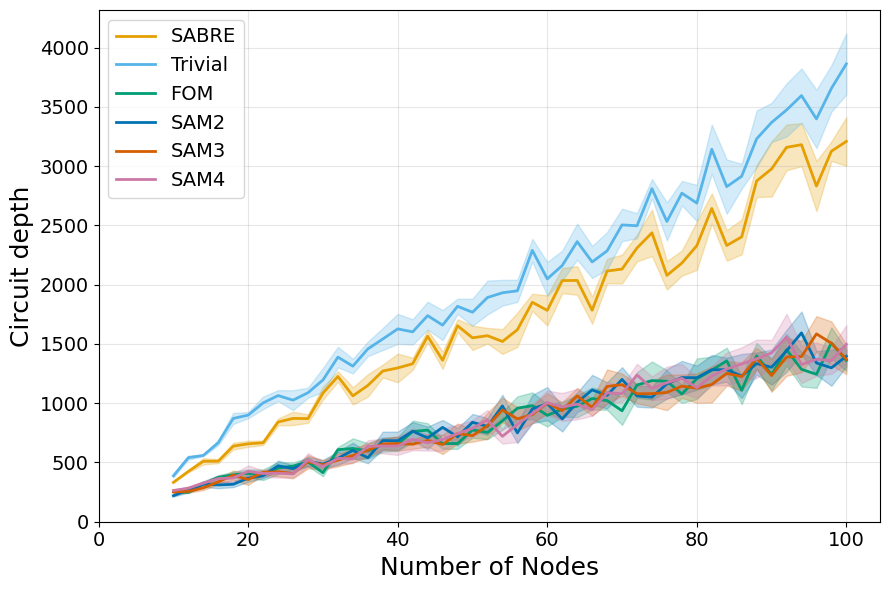

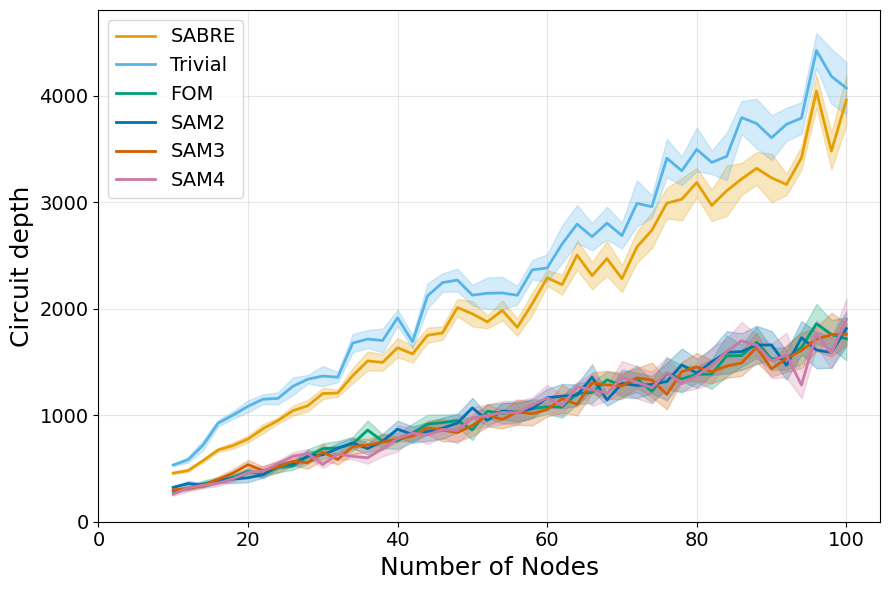

In [6]:

for metric, title, ylabel in quality_plots:
    print(f'Random regular graphs: {title}')
    plot_metric_results(
        results_reg, nodes_reg, k_list, params_reg, metric=metric,
        title_prefix=f'Random regular graphs: {title}', ylabel=ylabel,
    )

# BA Circuit Quality

Barabasi-Albert graphs: SWAP count


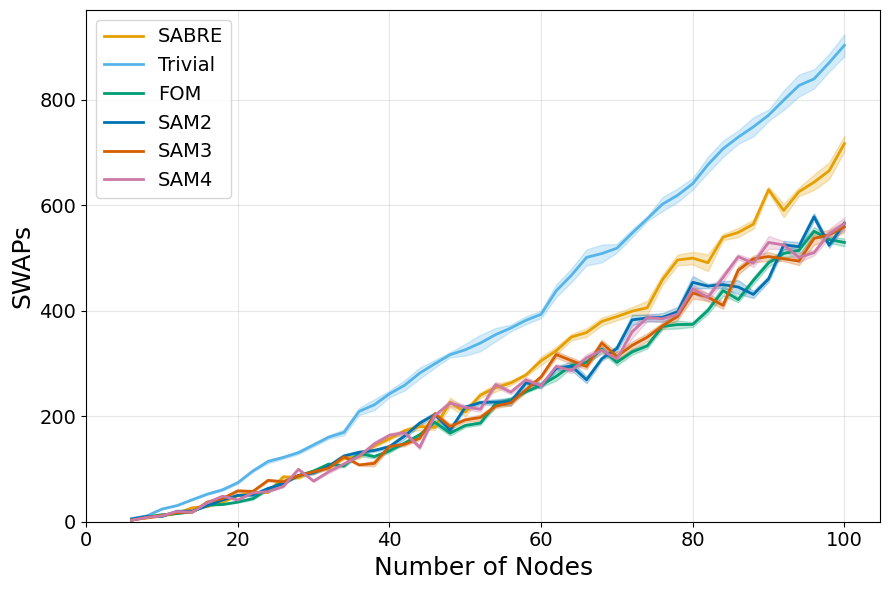

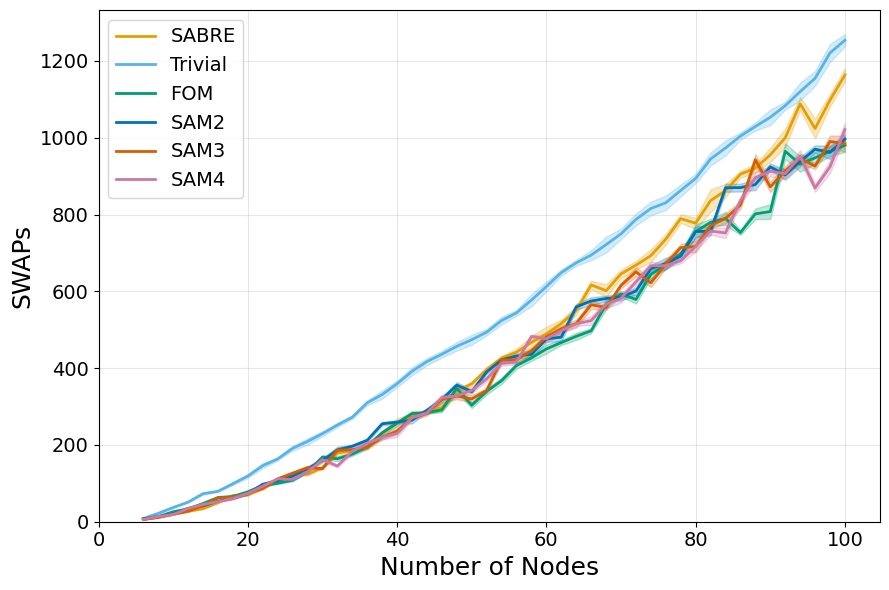

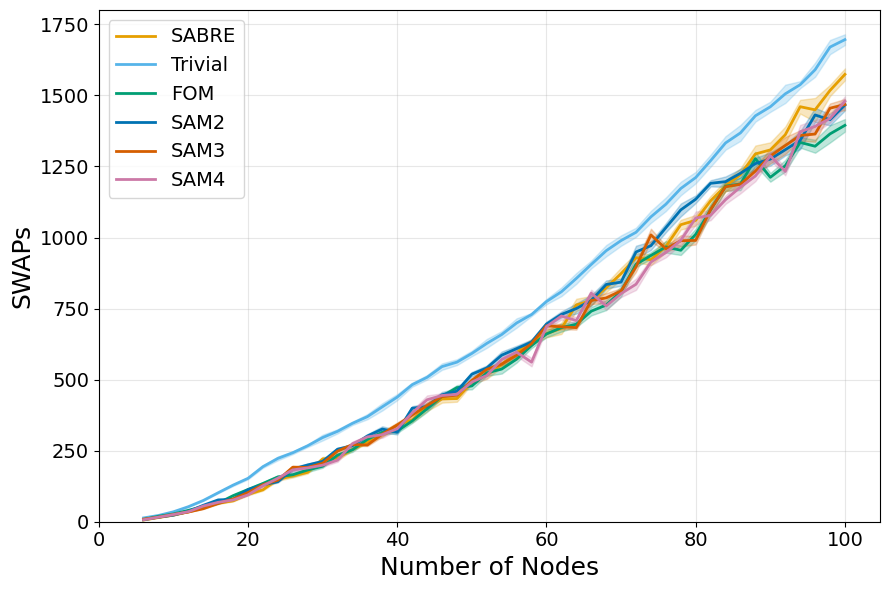

Barabasi-Albert graphs: Two-qubit gate count


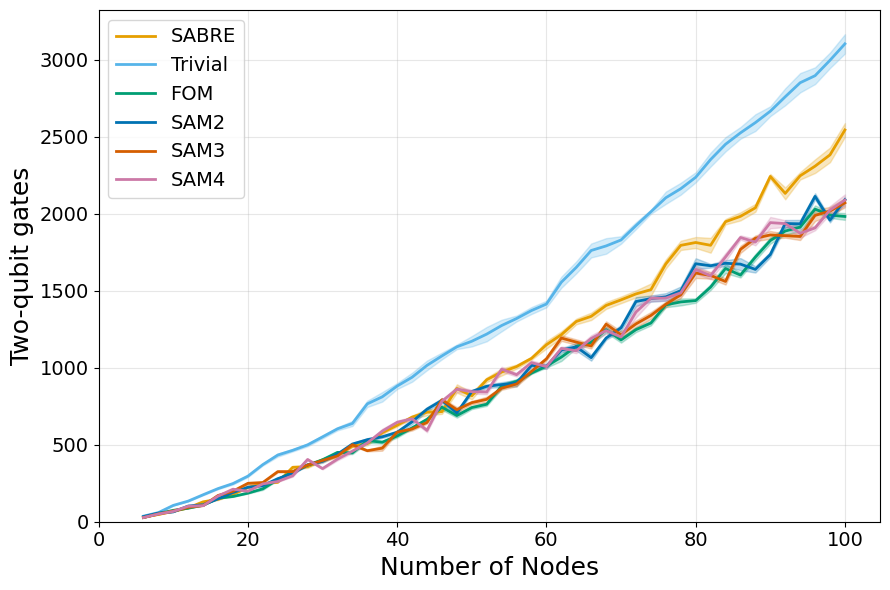

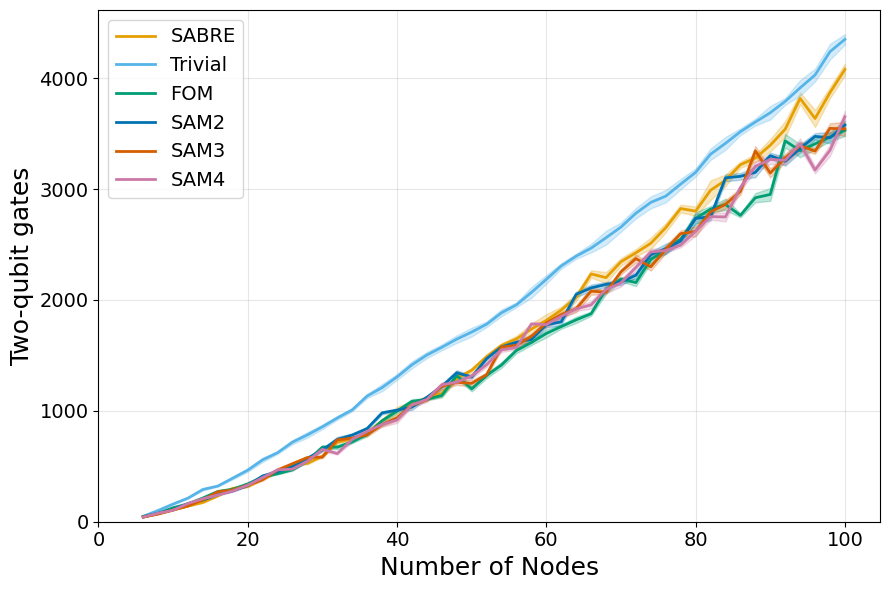

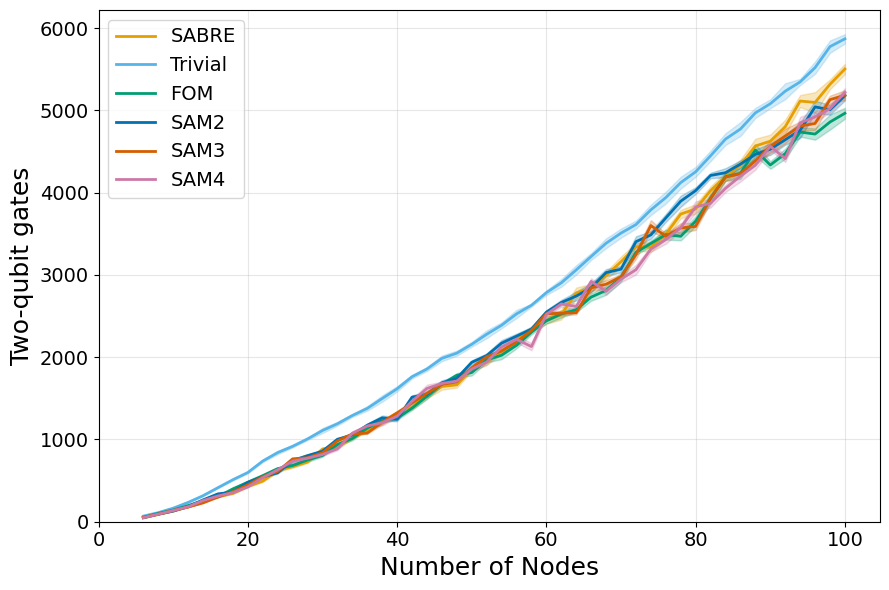

Barabasi-Albert graphs: Optimized circuit depth


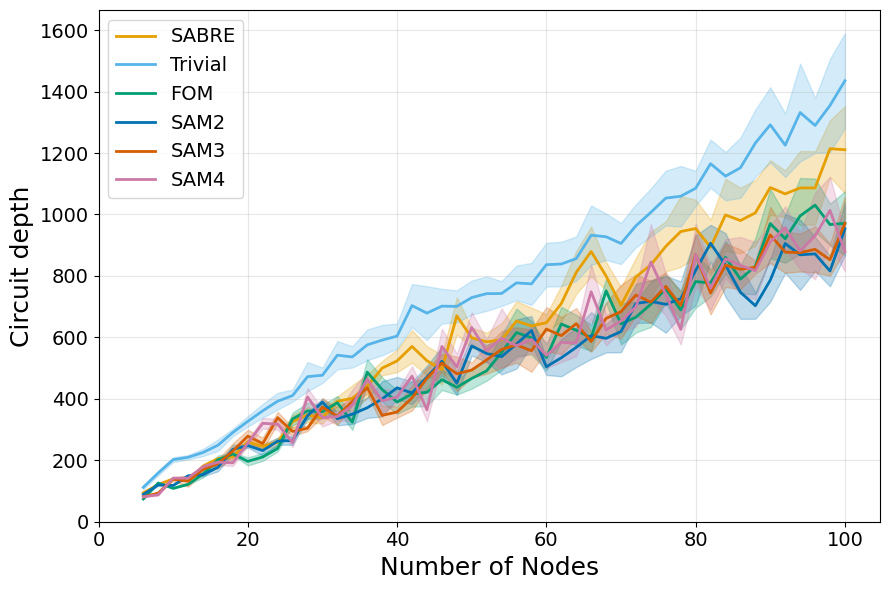

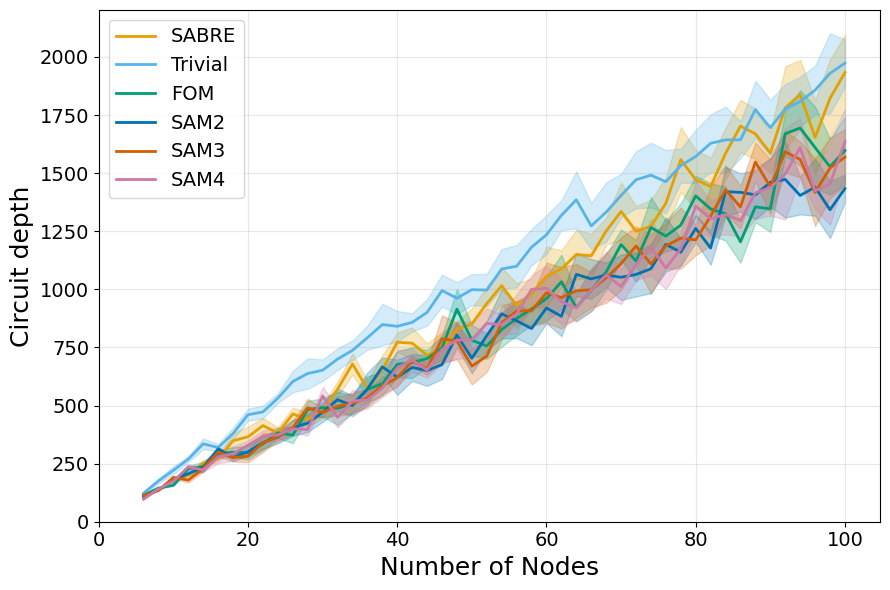

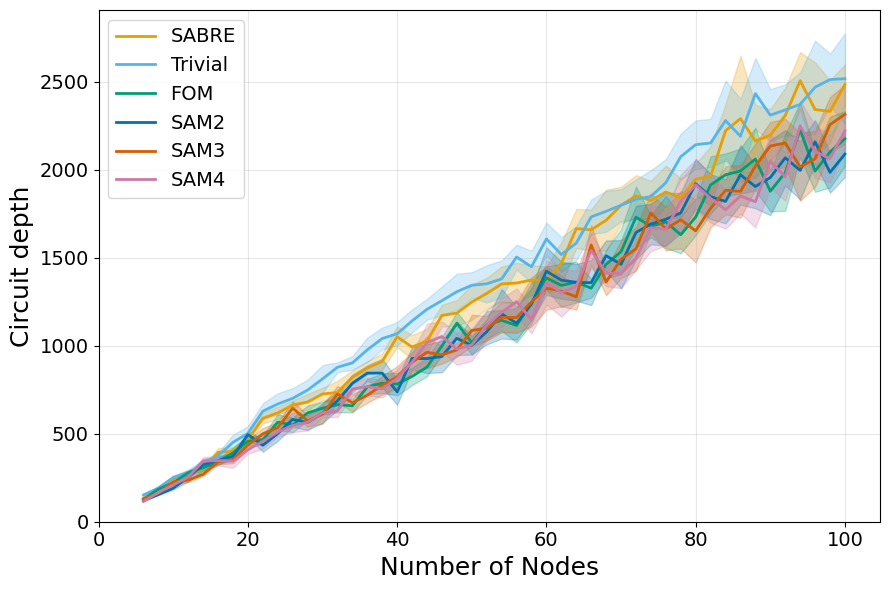

In [7]:
for metric, title, ylabel in quality_plots:
    print(f'Barabasi-Albert graphs: {title}')
    plot_metric_results(
        results_ba, nodes_ba, k_list, params_ba, metric=metric,
        title_prefix=f'Barabasi-Albert graphs: {title}', ylabel=ylabel,
    )

# RR Time

Random regular graphs: Mapping time


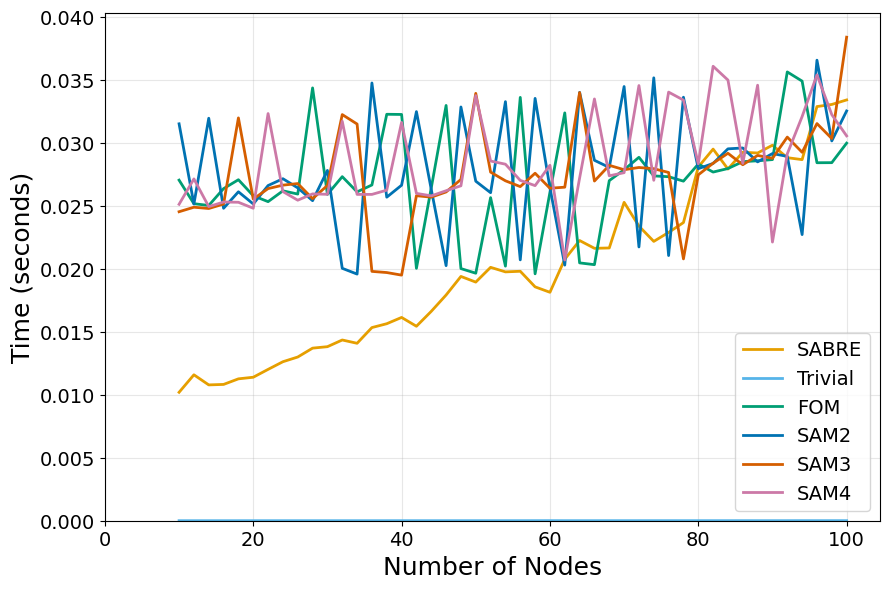

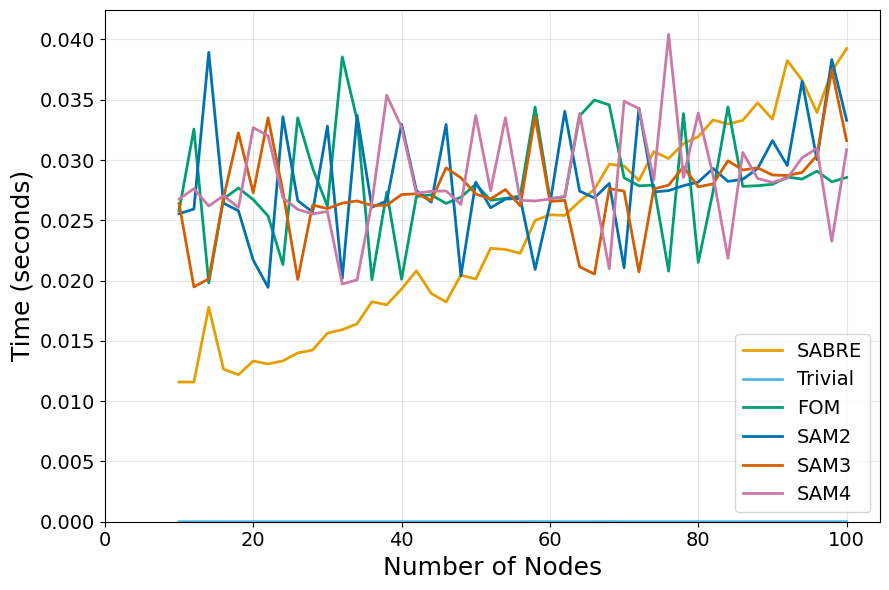

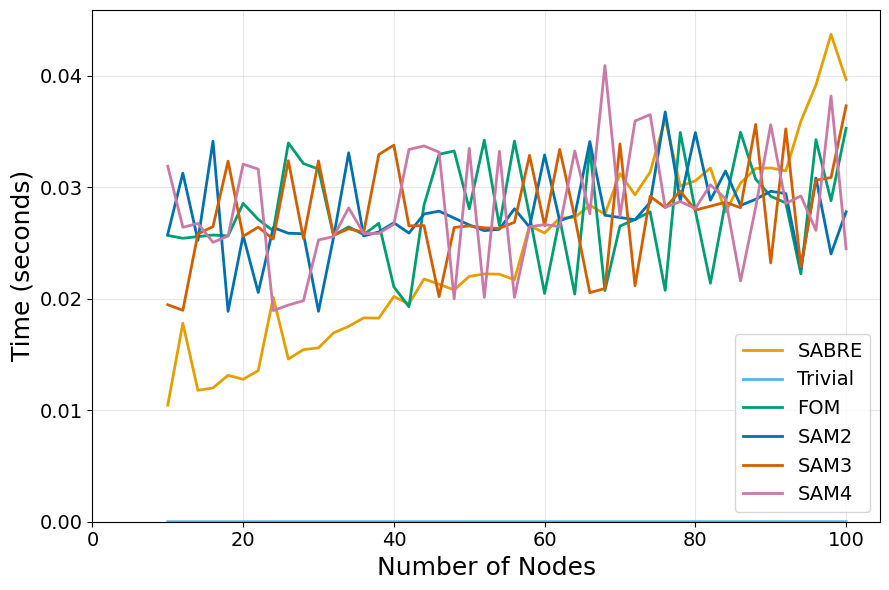

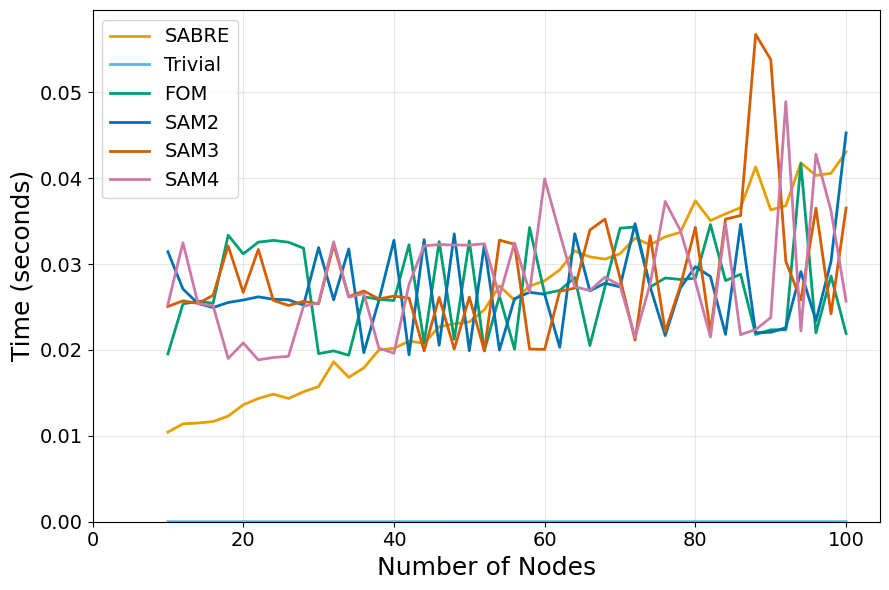

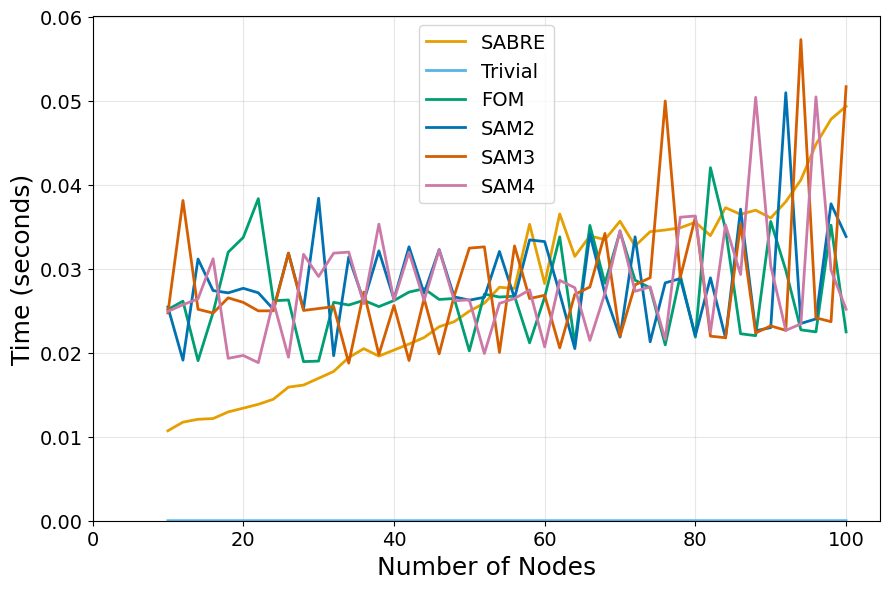

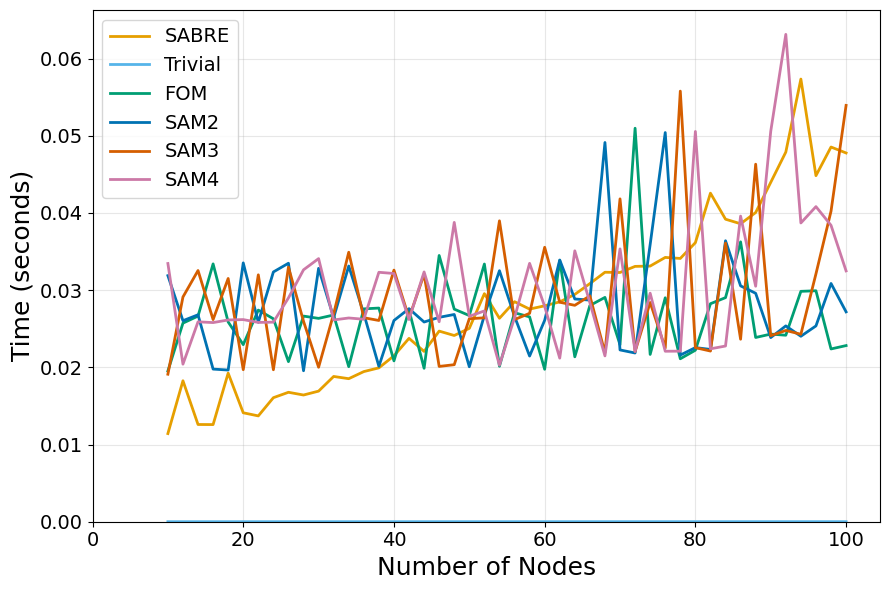

Random regular graphs: Initial circuit generation time


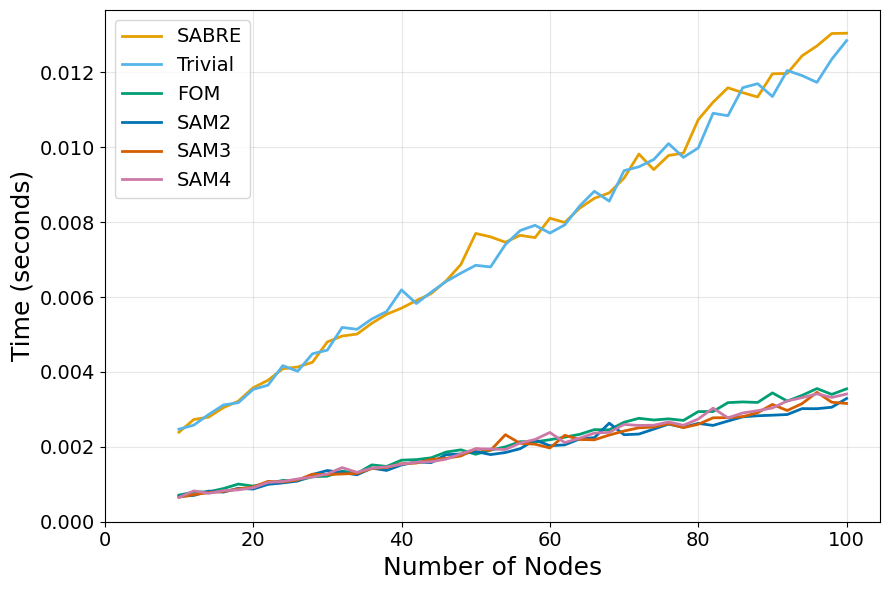

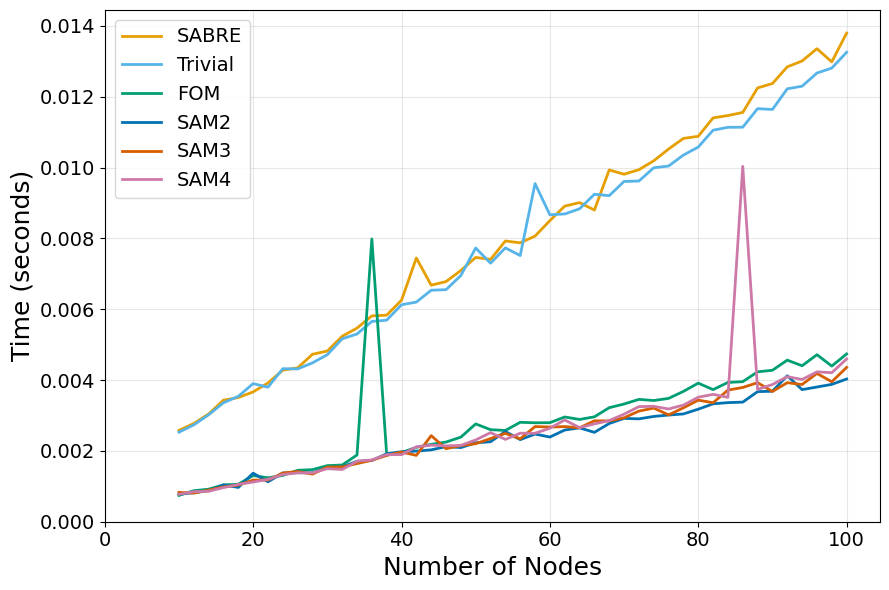

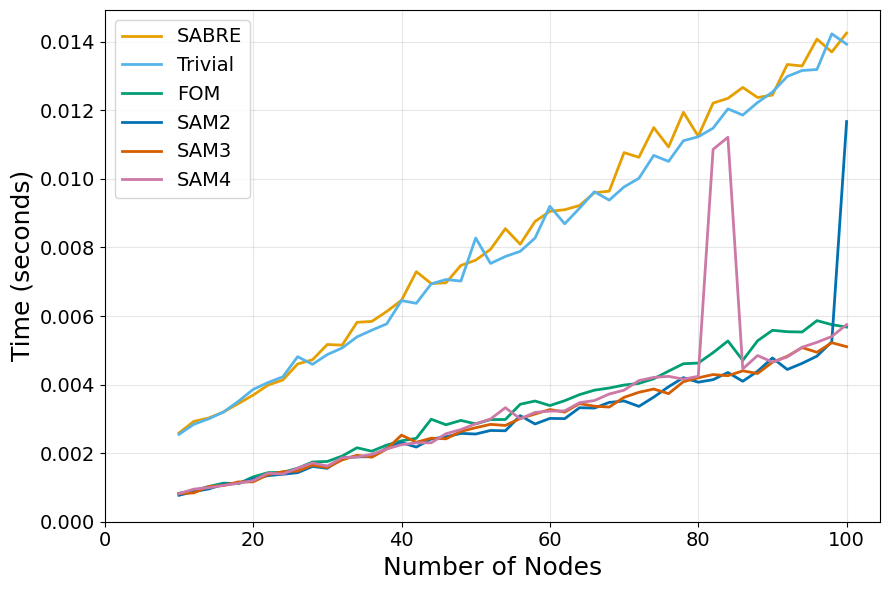

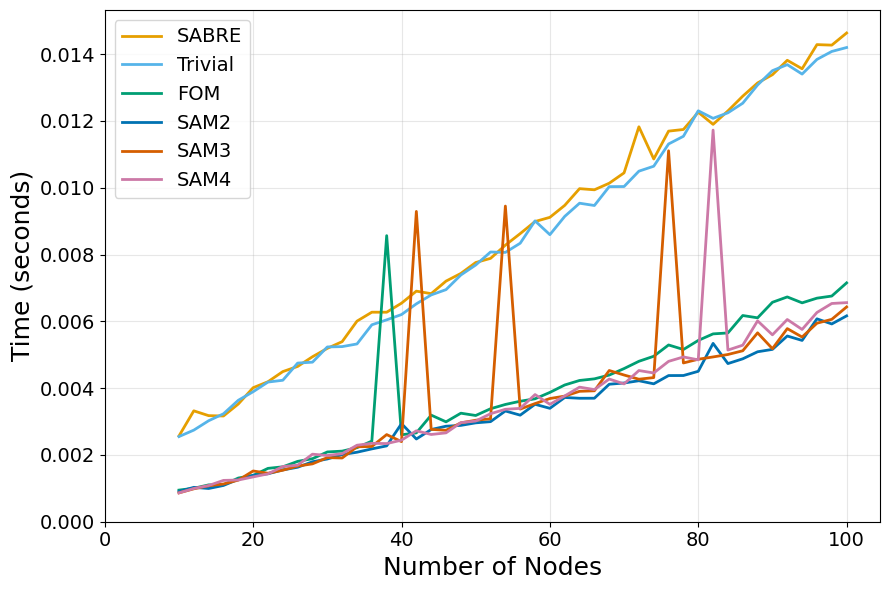

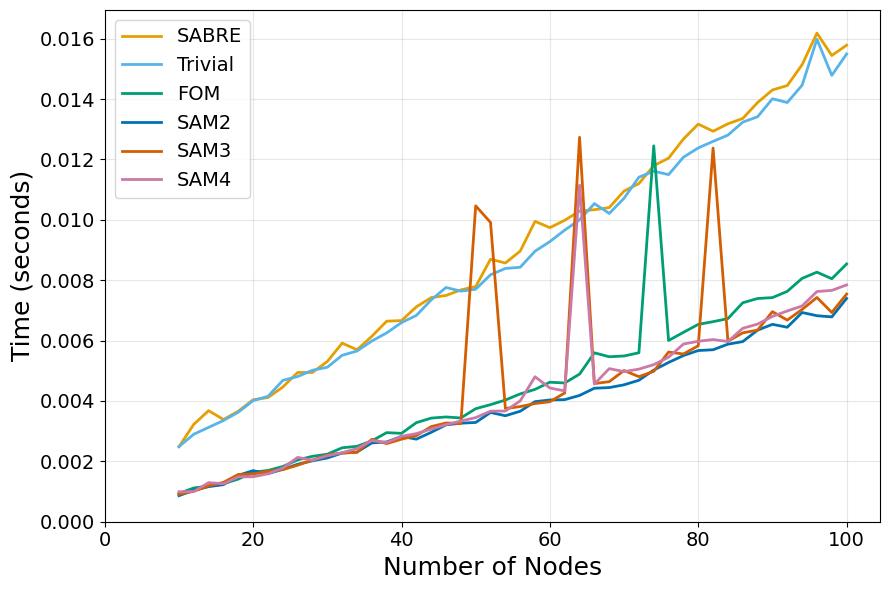

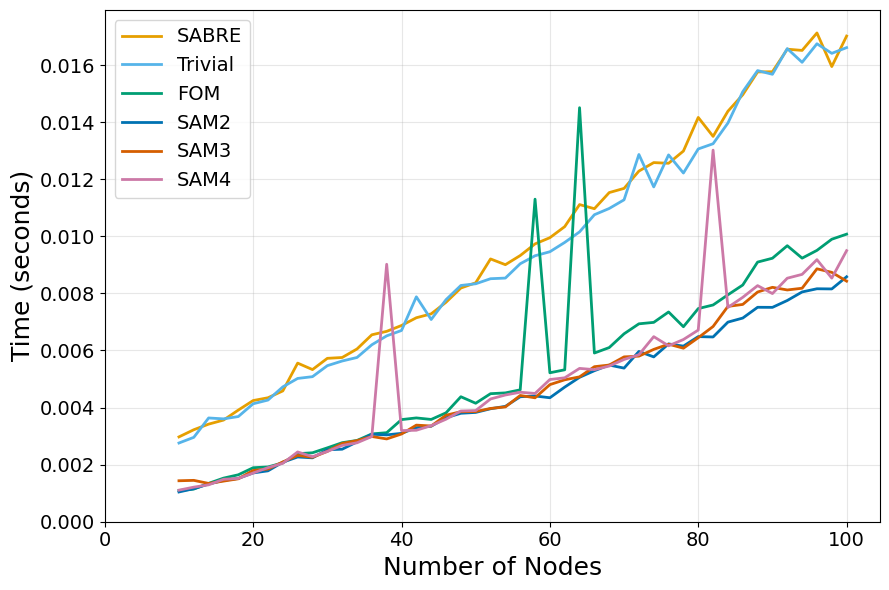

Random regular graphs: Routing time


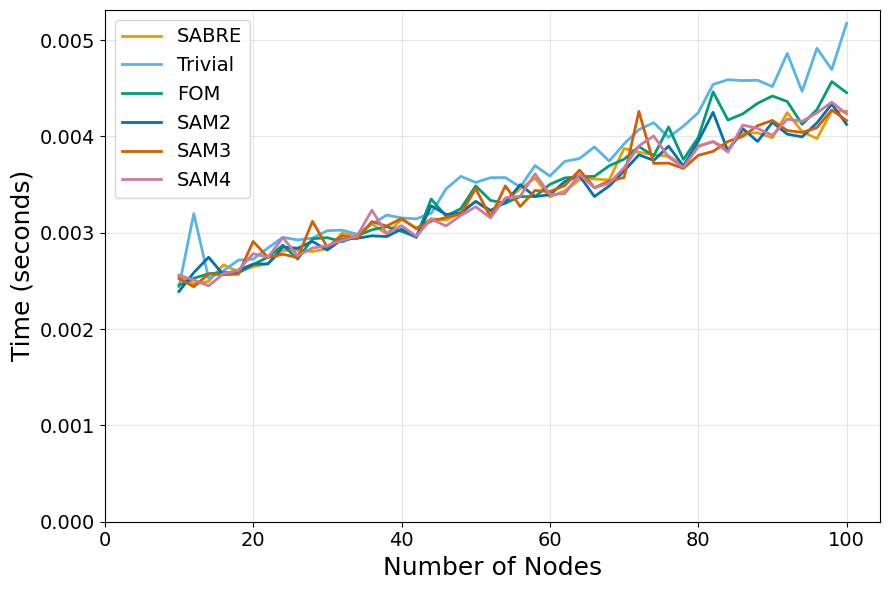

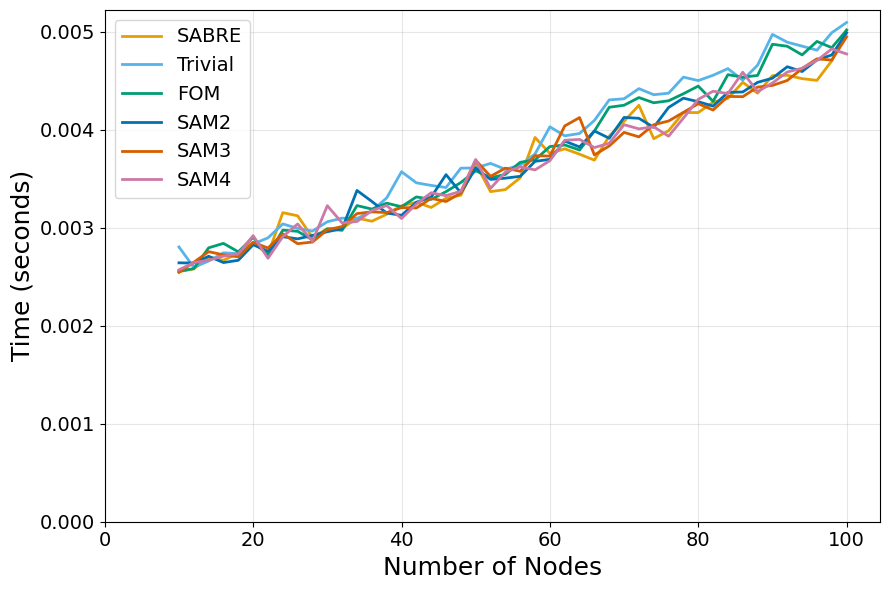

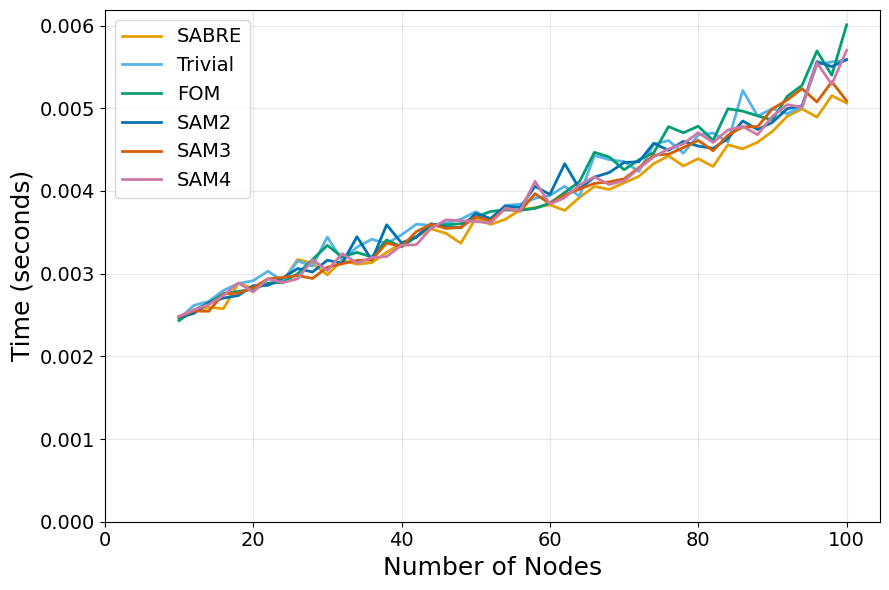

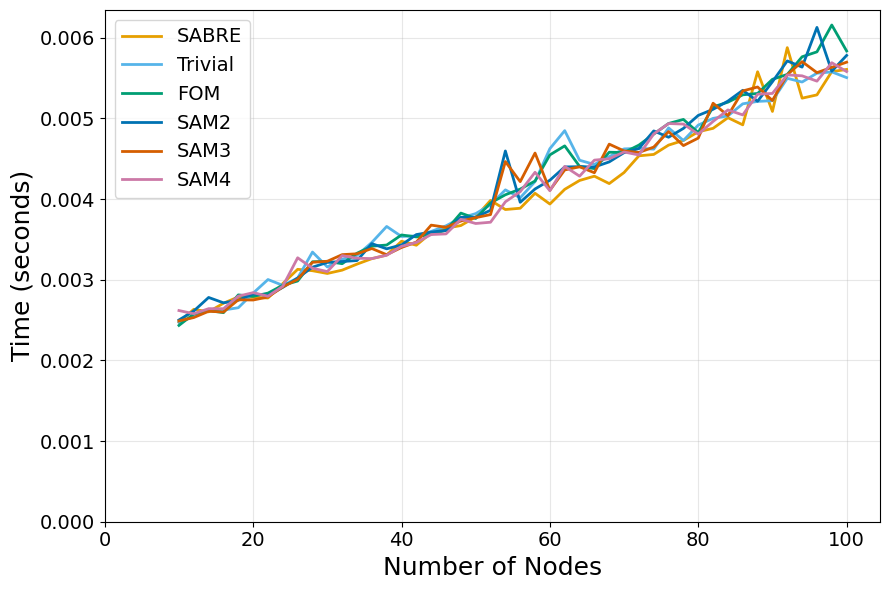

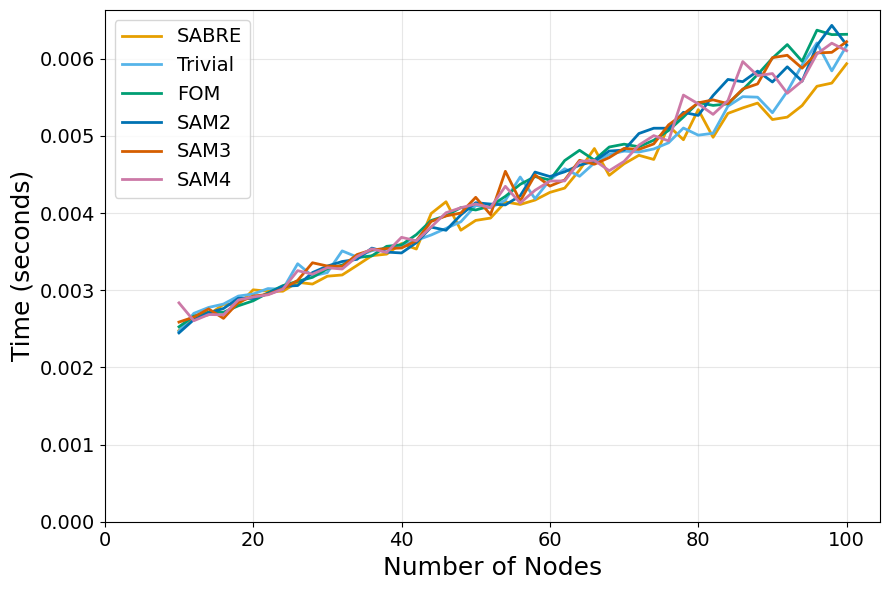

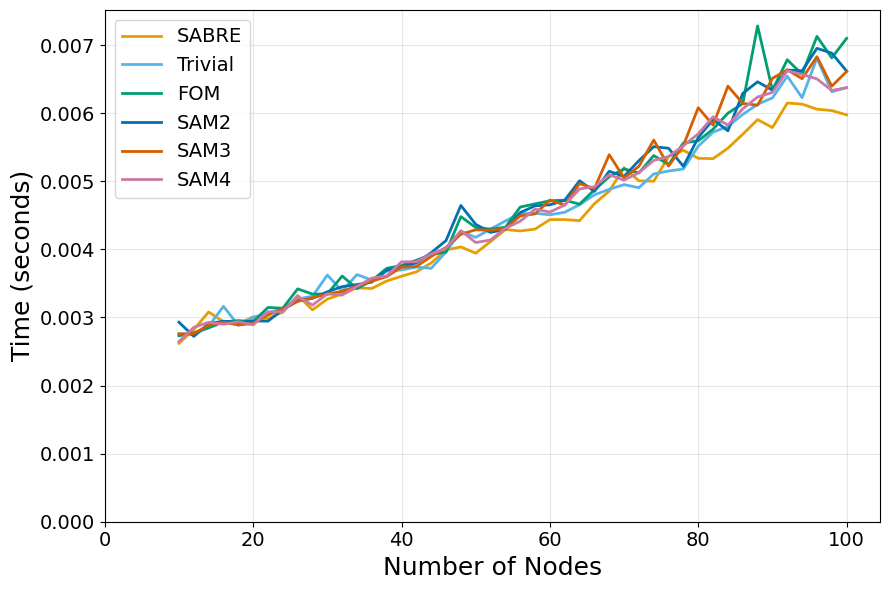

Random regular graphs: Final optimization time


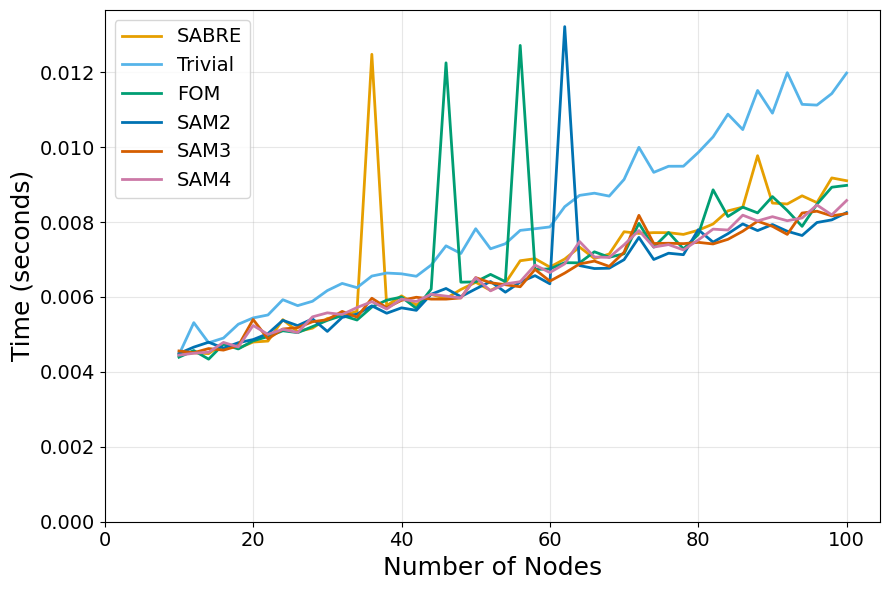

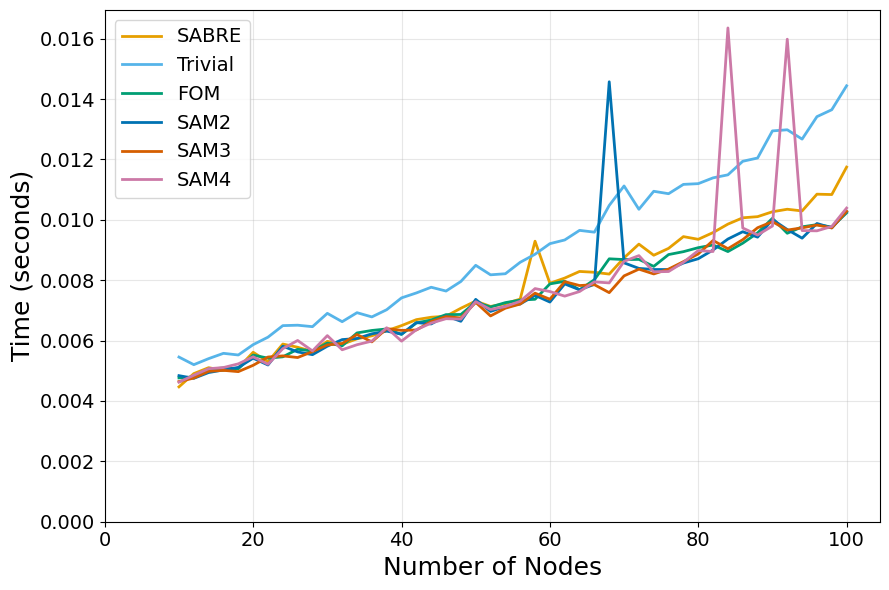

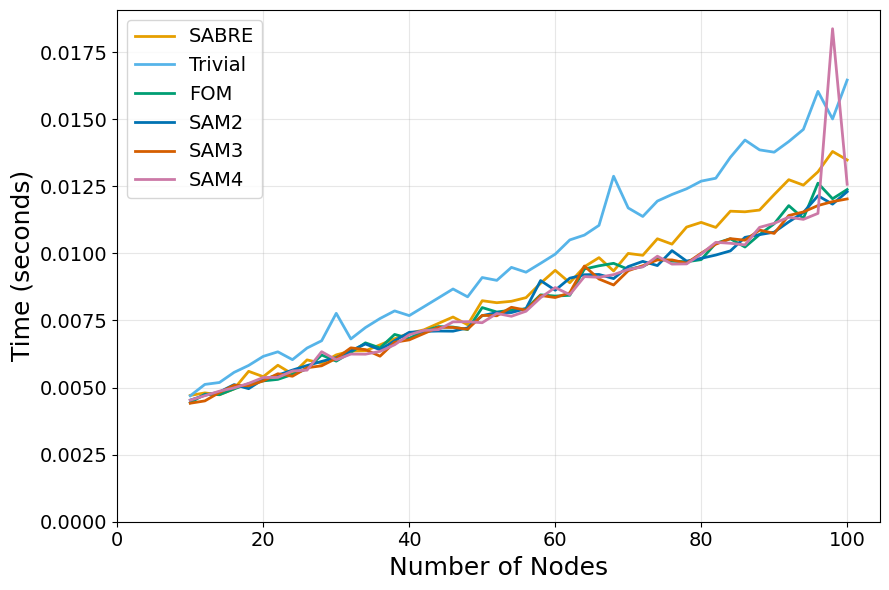

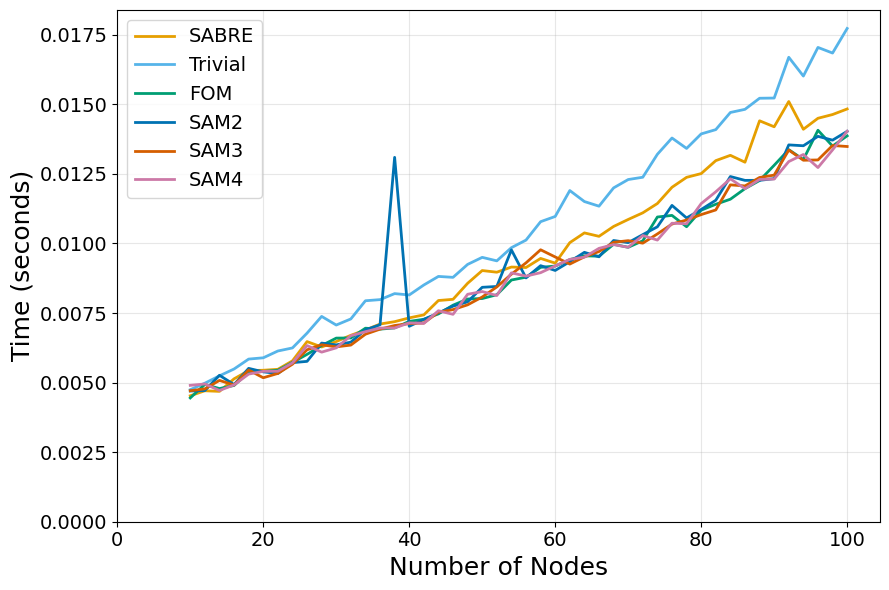

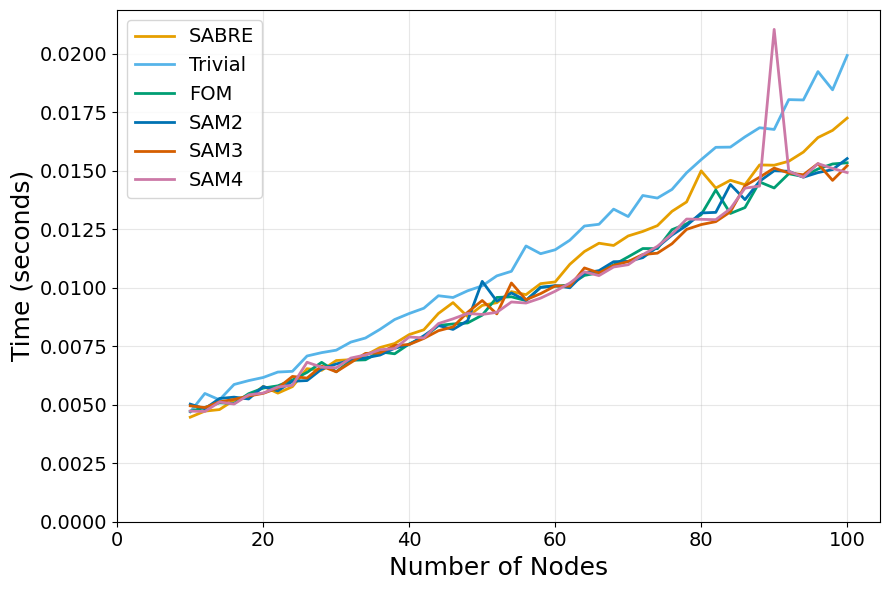

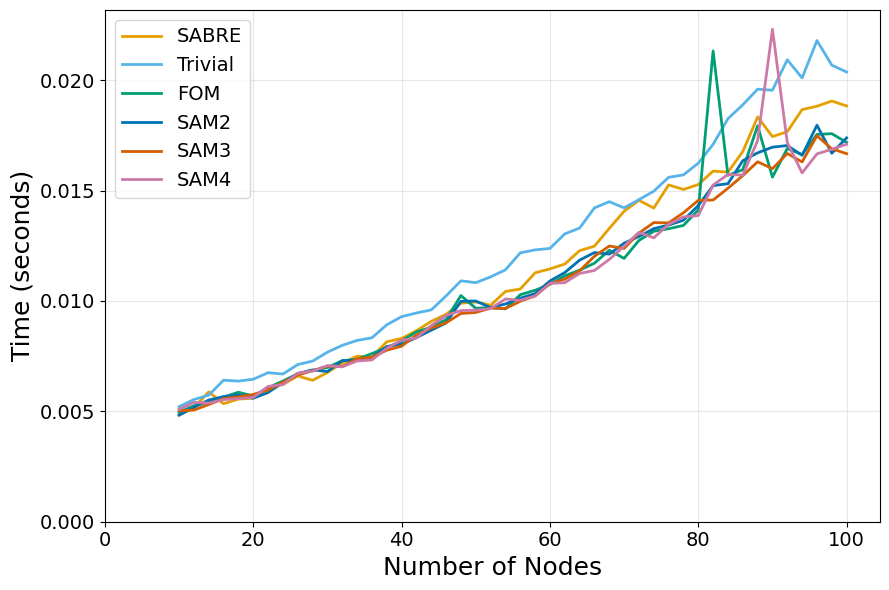

In [8]:

for metric, title, ylabel in time_plots:
    print(f'Random regular graphs: {title}')
    plot_metric_results(
        times_reg, nodes_reg, k_list, params_reg, metric=metric,
        title_prefix=f'Random regular graphs: {title}', ylabel=ylabel, fill_between=False,
    )



# BA Time

Barabasi-Albert graphs: Mapping time


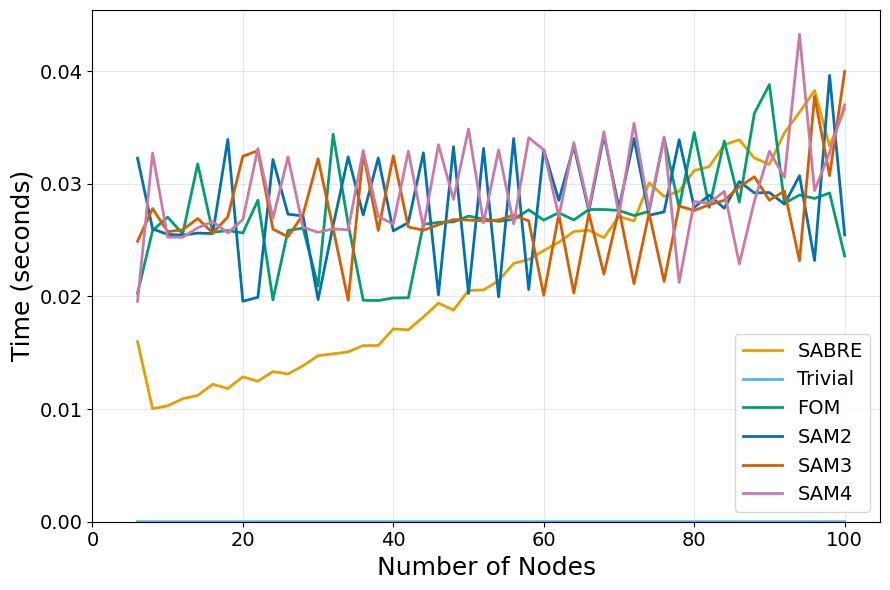

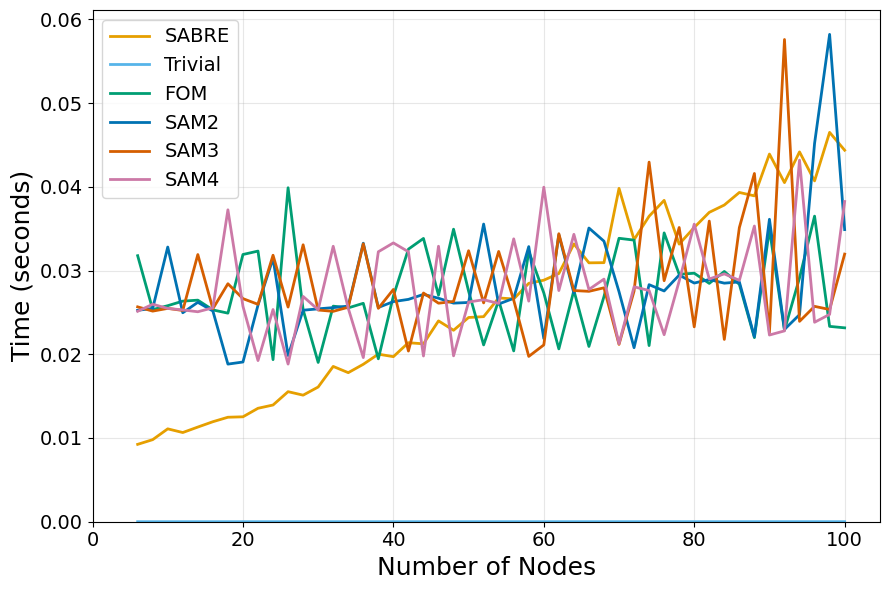

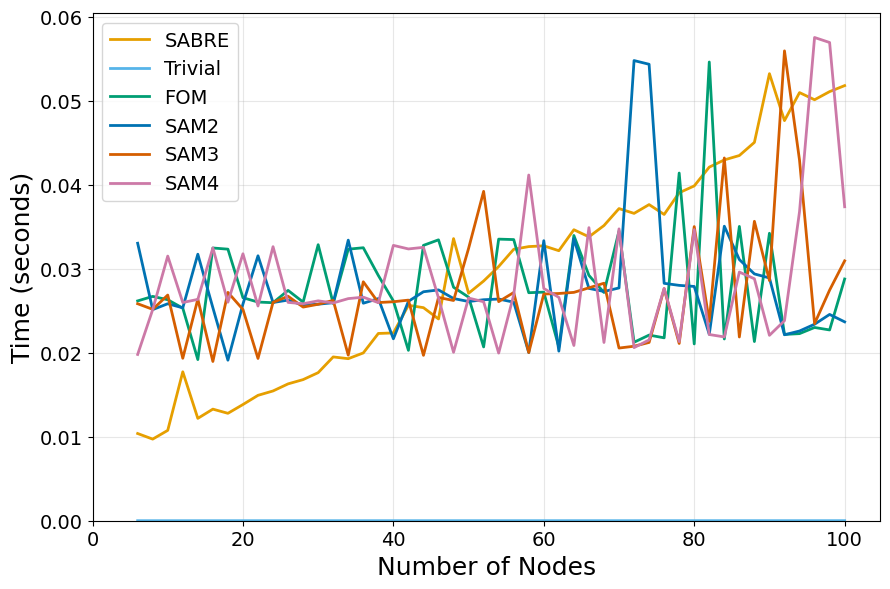

Barabasi-Albert graphs: Initial circuit generation time


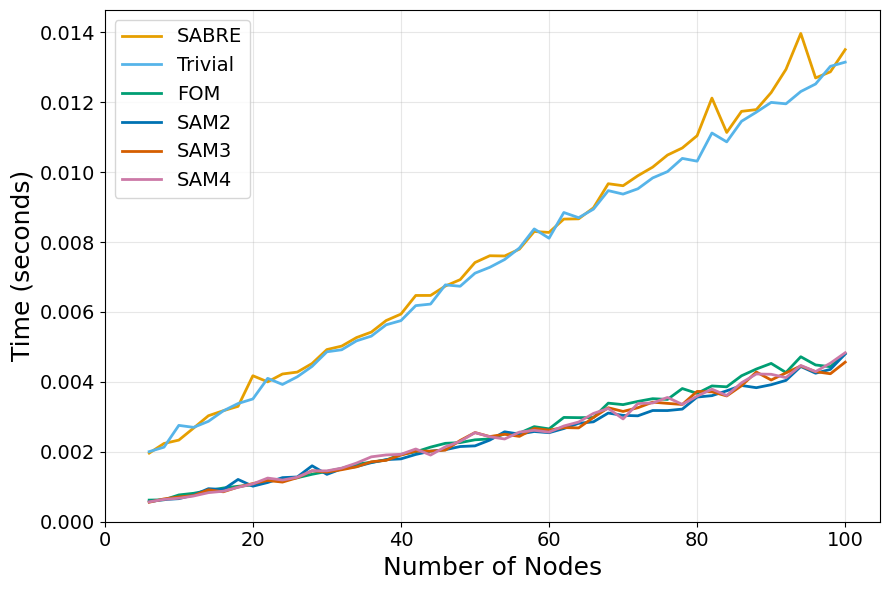

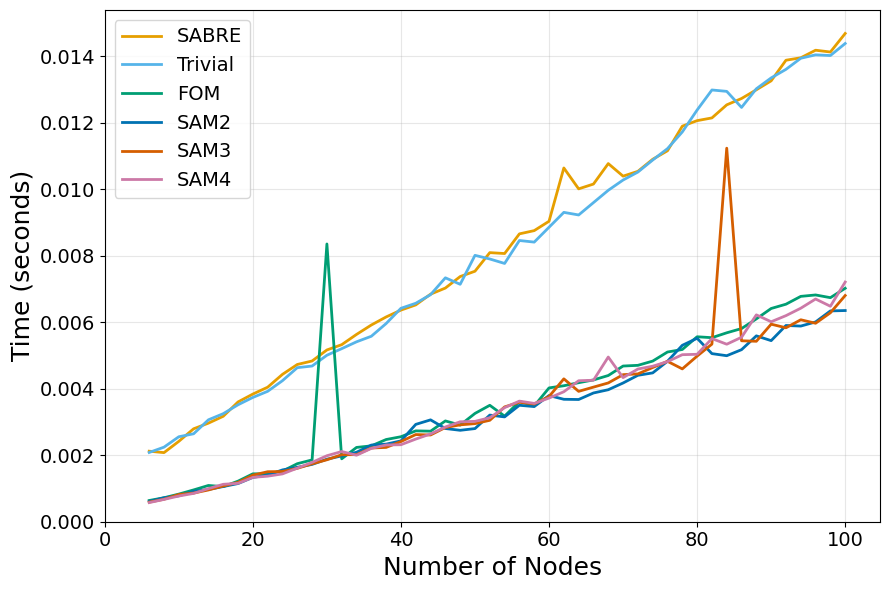

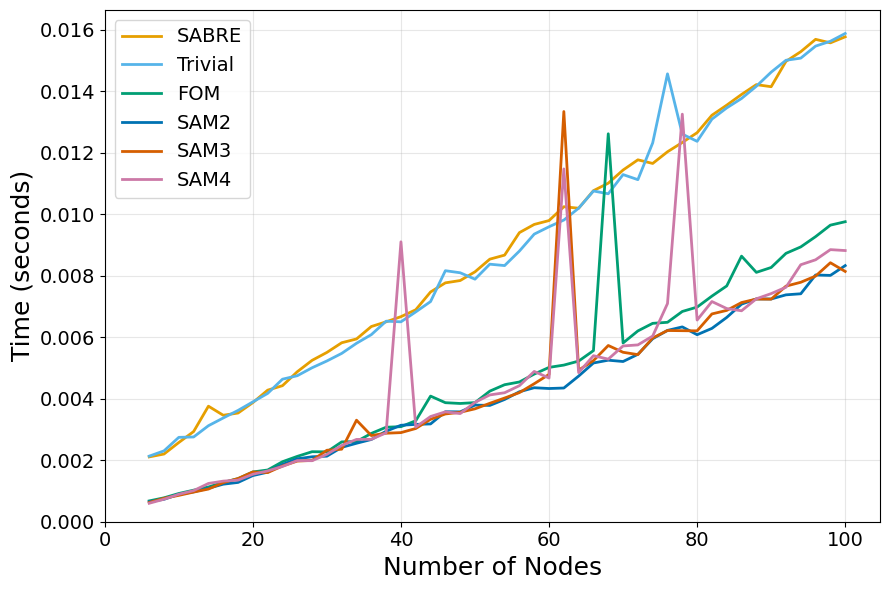

Barabasi-Albert graphs: Routing time


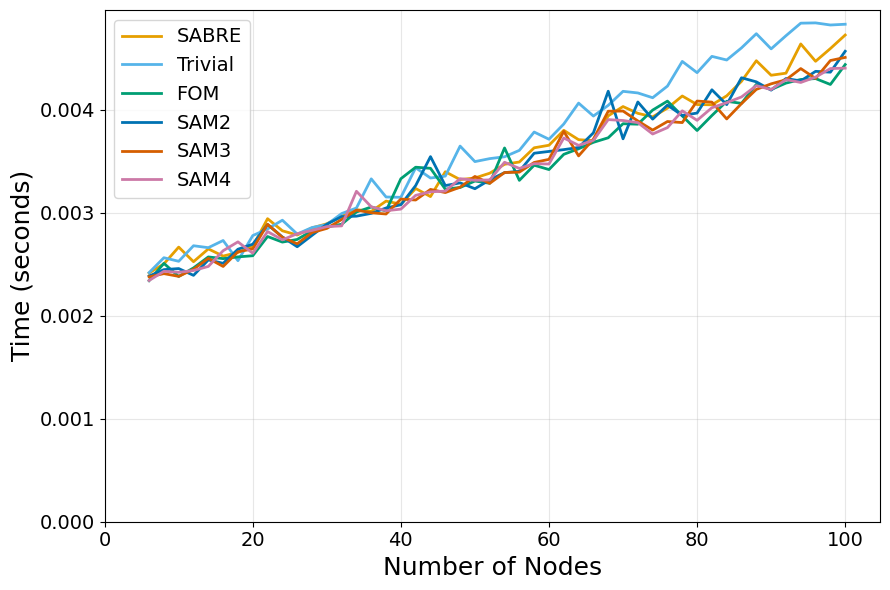

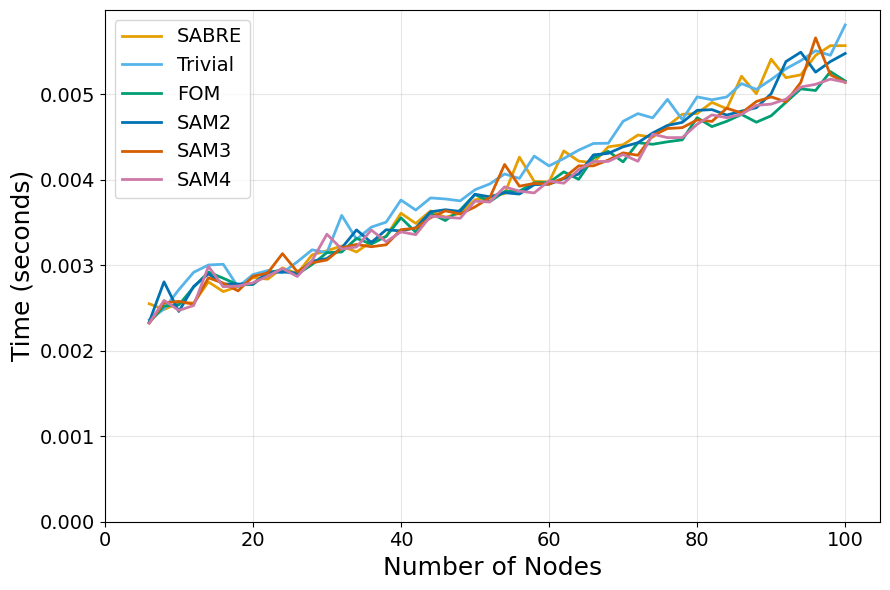

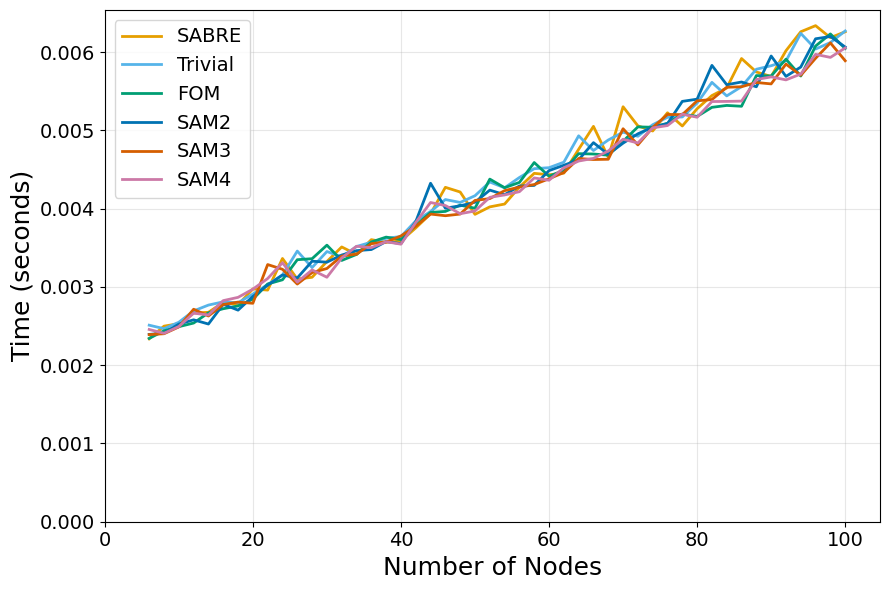

Barabasi-Albert graphs: Final optimization time


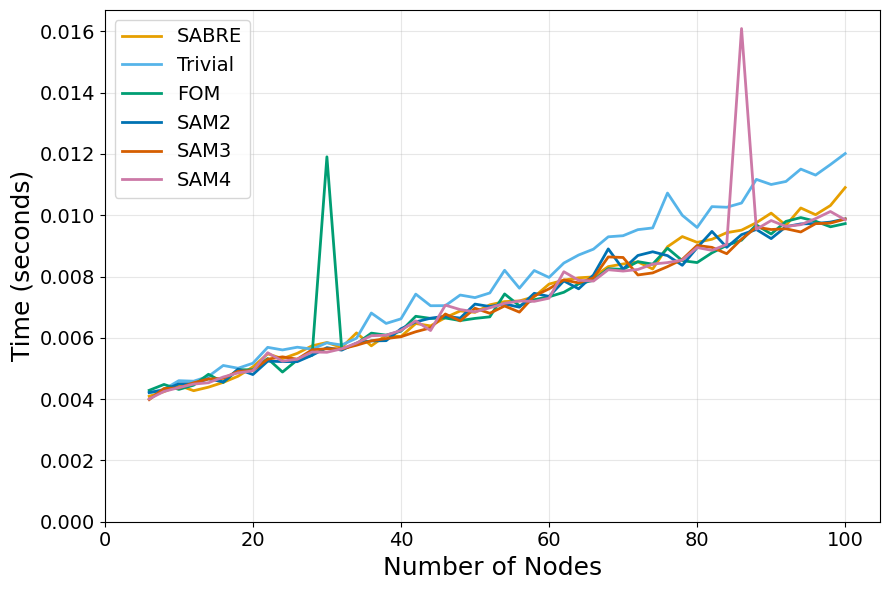

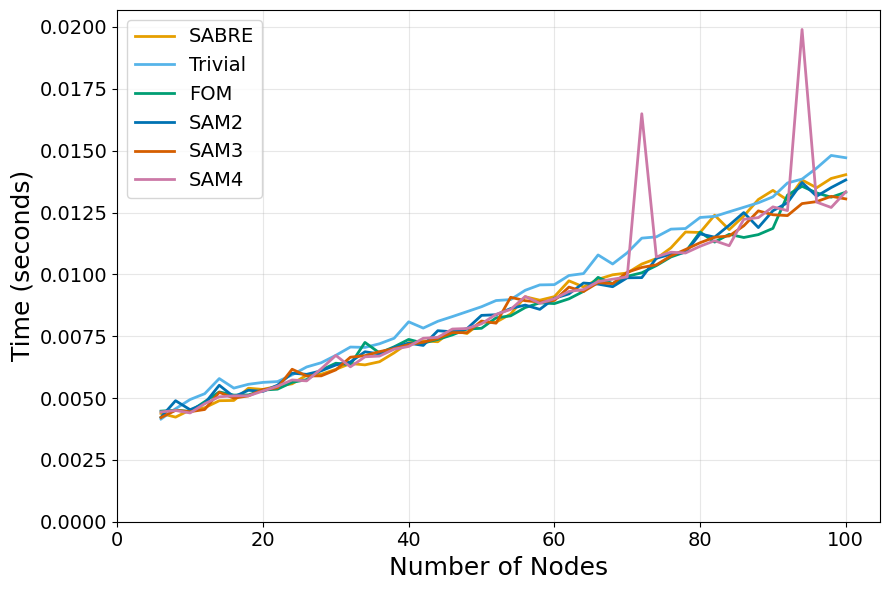

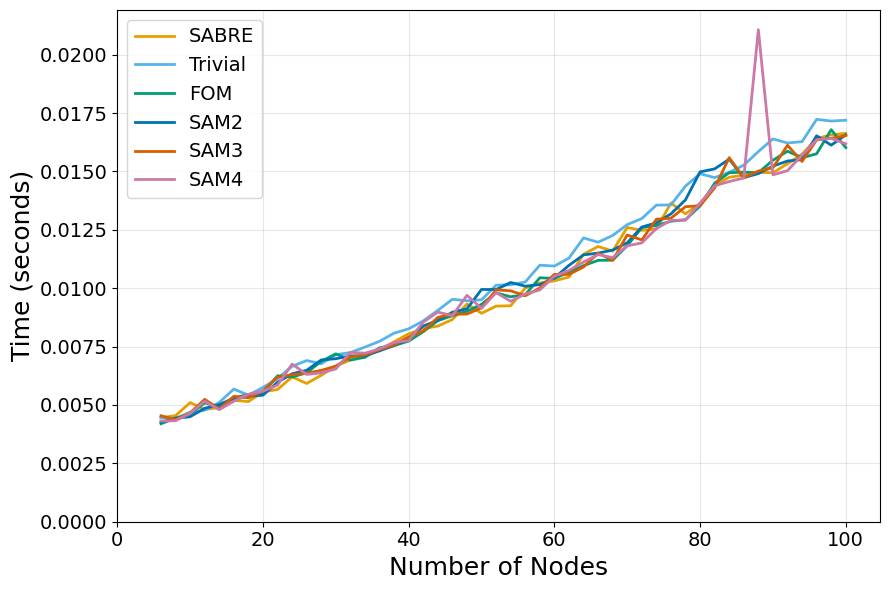

In [9]:
for metric, title, ylabel in time_plots:
    print(f'Barabasi-Albert graphs: {title}')
    plot_metric_results(
        times_ba, nodes_ba, k_list, params_ba, metric=metric,
        title_prefix=f'Barabasi-Albert graphs: {title}', ylabel=ylabel, fill_between=False,
    )